# Cache-Aware Structured Pruning for Energy-Efficient Deep Learning
## College-project experiment: DenseNet-BC-100-12 on CIFAR-10

This notebook compares:
1. An unpruned baseline DenseNet-BC-100-12.
2. Conventional dependency-aware structured pruning.
3. A layer-wise cache-aware structured-pruning policy.

**Recommended runtime configuration:** 30 baseline epochs and 8 fine-tuning epochs for each pruned model. This is a practical starting point for a college project, not a guarantee of state-of-the-art CIFAR-10 accuracy. Run the smoke test first, then run the full experiment. Use the same dataset split, seed, batch size, precision policy, and evaluation procedure for all three models.

**Research limitation:** the cache policy uses estimated per-layer weight/activation working-set sizes and a configurable L2-cache reference. These are proxies, not direct measurements of cache misses or cache hits. Do not claim measured cache behavior unless hardware performance counters are collected separately.

The notebook saves metrics, training histories, pruning reports, plots, metadata, and a research summary under `results/`. The full run uses a new run tag (`college_v1_30e`) so it does not silently reuse checkpoints from the earlier 100-epoch configuration.


**Audit status:** All code cells pass static Python syntax parsing. The notebook has not been run end-to-end on the target computer in this review. In particular, `torch-pruning` version compatibility, CIFAR-10 download, actual physical channel pruning, and GPU power telemetry must be verified during the smoke test. The compact results table uses the actual metric names produced by the notebook.


## 1. Experiment configuration

All paths, training settings, pruning targets, hardware measurement counts, and DenseNet-BC parameters are controlled from the configuration cell below. `NUM_WORKERS=0` is the notebook-safe default. The smoke test uses the full dataset but fewer epochs; it is a pipeline validation, not a final research result.


## Runtime and execution guidance

1. Run cells in order from top to bottom.
2. First set `SMOKE_TEST = True` and run the notebook to confirm data download, model construction, pruning, evaluation, and artifact generation work end to end. Smoke-test metrics are **not** research results.
3. Then set `SMOKE_TEST = False` and rerun from the configuration cell.
4. The full configuration uses 30 baseline epochs and 8 fine-tuning epochs for each pruned model (46 training epochs total across the three models). CUDA mixed precision is enabled when supported; CPU runs stay in FP32.
5. If the run is interrupted, set `RESUME_TRAINING=1` in the environment before running the training cells. Do not resume from checkpoints created with a different configuration. The new run tag avoids colliding with the previous `full` run.
6. Use validation accuracy to select checkpoints. Evaluate the test set only for final comparisons, and report the measured results rather than assuming pruning improves latency or energy on every device.


In [54]:
from pathlib import Path
import os, random, time, gc, json, math, pickle, subprocess, sys, logging, platform, hashlib, inspect, threading, datetime

SEED = 42
DENSENET_DEPTH = 100
DENSENET_GROWTH_RATE = 12
DENSENET_BOTTLENECK_SIZE = 4
DENSENET_COMPRESSION = 0.5

PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULT_ROOT = PROJECT_ROOT / "results"
PLOT_ROOT = RESULT_ROOT / "plots"
for _p in (DATA_ROOT, CHECKPOINT_ROOT, RESULT_ROOT, PLOT_ROOT):
    _p.mkdir(parents=True, exist_ok=True)

CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
CIFAR_ARCHIVE = DATA_ROOT / "cifar-10-python.tar.gz"
MEMMAP_ROOT = DATA_ROOT / "cifar10_memmap"

# Keep True for a short end-to-end validation. Set False for research results.
SMOKE_TEST = False  # Set True for a short pipeline check before the full run.
BATCH_SIZE = 128
NUM_WORKERS = 0  # Notebook-compatible default.
VAL_SIZE = 5000
SMOKE_TRAIN_IMAGES = 2048
SMOKE_VAL_IMAGES = 512
SMOKE_TEST_IMAGES = 1024

BASELINE_EPOCHS = 1 if SMOKE_TEST else 30
FINETUNE_EPOCHS = 1 if SMOKE_TEST else 8
ENERGY_BATCHES = 5 if SMOKE_TEST else 30
ENERGY_WARMUP_BATCHES = 2 if SMOKE_TEST else 5
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9
USE_AMP = True  # Uses mixed precision only on CUDA; CPU automatically remains FP32.

CONVENTIONAL_PRUNING_RATIO = 0.20
CACHE_AWARE_MAX_RATIO = 0.30
CACHE_AWARE_MIN_RATIO = 0.05
CACHE_POLICY_SPREAD = 0.08
L2_CACHE_MB_OVERRIDE = None  # Optional: set a measured device L2-cache size in MiB; None uses detection/fallback.
MAC_REDUCTION_TOLERANCE_PP = 5.0
ROUND_TO = 4
POWER_SAMPLE_INTERVAL_SEC = 0.05
IDLE_POWER_SAMPLE_SEC = 0.5

RUN_TAG = "smoke" if SMOKE_TEST else "college_v1_30e"
BASELINE_BEST_CKPT = CHECKPOINT_ROOT / f"baseline_best_{RUN_TAG}.pt"
BASELINE_LATEST_CKPT = CHECKPOINT_ROOT / f"baseline_latest_{RUN_TAG}.pt"
CONVENTIONAL_BEST_CKPT = CHECKPOINT_ROOT / f"conventional_pruned_best_{RUN_TAG}.pt"
CONVENTIONAL_LATEST_CKPT = CHECKPOINT_ROOT / f"conventional_pruned_latest_{RUN_TAG}.pt"
CACHE_BEST_CKPT = CHECKPOINT_ROOT / f"cache_aware_pruned_best_{RUN_TAG}.pt"
CACHE_LATEST_CKPT = CHECKPOINT_ROOT / f"cache_aware_pruned_latest_{RUN_TAG}.pt"

LOG_PATH = RESULT_ROOT / "run.log"
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", handlers=[logging.FileHandler(LOG_PATH, mode="a", encoding="utf-8"), logging.StreamHandler()], force=True)
logging.info("Starting %s run; smoke_test=%s", RUN_TAG, SMOKE_TEST)

print("Project root:", PROJECT_ROOT)
print("Device is selected after imports in the device-check cell.")
print("Run mode:", RUN_TAG, "| smoke test:", SMOKE_TEST)
print("DenseNet depth/growth/compression:", DENSENET_DEPTH, DENSENET_GROWTH_RATE, DENSENET_COMPRESSION)
print("Batch size:", BATCH_SIZE, "| workers:", NUM_WORKERS)
print("Baseline epochs:", BASELINE_EPOCHS, "| fine-tuning epochs:", FINETUNE_EPOCHS)
print("AMP enabled by configuration:", USE_AMP)

2026-10-29 01:18:25,739 | INFO | Starting college_v1_30e run; smoke_test=False


Project root: c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW
Device is selected after imports in the device-check cell.
Run mode: college_v1_30e | smoke test: False
DenseNet depth/growth/compression: 100 12 0.5
Batch size: 128 | workers: 0
Baseline epochs: 30 | fine-tuning epochs: 8
AMP enabled by configuration: True


## 2. Install/check required Python packages

**What happens in this cell:**  
The notebook checks for the libraries it needs. It installs missing packages into the current Python environment.

The important optional packages are:

- `torch-pruning` — dependency-aware structured pruning.
- `pynvml` — direct NVIDIA GPU power measurements.
- `fvcore` — FLOP/MAC analysis.

If your environment is offline, install these packages manually and rerun the cell.

In [55]:
import importlib.util
import subprocess
import sys

REQUIRED = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
    "torch_pruning": "torch-pruning",
}
OPTIONAL = {"pynvml": "nvidia-ml-py"}
missing_required = [package for module, package in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing_required:
    print("Installing required packages:", missing_required)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_required])
    except Exception as exc:
        raise RuntimeError("Required packages could not be installed. Ensure the environment has internet/package access and a PyTorch-compatible torch-pruning installation. Physical structured pruning cannot proceed without torch-pruning.") from exc

for module, package in OPTIONAL.items():
    if importlib.util.find_spec(module) is None:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", package])
        except Exception as exc:
            print(f"WARNING: optional package {package} unavailable ({exc!r}). GPU power/energy telemetry will be marked unavailable.")

print("Dependency check complete. torch-pruning is mandatory; NVML is optional.")

Dependency check complete. torch-pruning is mandatory; NVML is optional.


## 3. Import libraries and configure reproducibility

**What happens in this cell:**  
Imports PyTorch, torchvision, NumPy, pandas, plotting tools, NVML and torch-pruning. It also configures deterministic/random seeds where practical.

In [56]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch_pruning as tp

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

try:
    import pynvml
    NVML_IMPORT_OK = True
except Exception:
    NVML_IMPORT_OK = False

try:
    from fvcore.nn import FlopCountAnalysis
    FVCORE_OK = True
except Exception:
    FVCORE_OK = False

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("PyTorch:", torch.__version__)
print("Torchvision imported.")
print("Torch-Pruning:", tp.__version__ if hasattr(tp, "__version__") else "installed")
print("FVCore available:", FVCORE_OK)
print("NVML available:", NVML_IMPORT_OK)


PyTorch: 2.14.1+cu126
Torchvision imported.
Torch-Pruning: 1.6.0
FVCore available: True
NVML available: True


## 4. Check GPU and NVML

**What happens in this cell:**  
Confirms whether PyTorch can see the GPU and checks whether NVIDIA Management Library (NVML) can expose power readings.

Energy results are only reported as measured GPU energy when NVML successfully provides power data. The notebook does not invent energy from FLOPs.

> **NVML warning:** If PyTorch prints a `pynvml package is deprecated` warning,
> it is only a warning and does not cause the training failure. The notebook
> can continue; energy measurement still requires NVIDIA NVML support.


In [57]:

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print("VRAM GB:", round(props.total_memory / (1024**3), 2))
    print("Compute capability:", f"{props.major}.{props.minor}")
else:
    print("WARNING: CUDA is not available. Training will run on CPU.")

NVML_OK = False
NVML_HANDLE = None

if NVML_IMPORT_OK and DEVICE.type == "cuda":
    try:
        pynvml.nvmlInit()
        NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)
        NVML_OK = True

        name = pynvml.nvmlDeviceGetName(NVML_HANDLE)
        power_mw = pynvml.nvmlDeviceGetPowerUsage(NVML_HANDLE)

        print("NVML GPU:", name.decode() if isinstance(name, bytes) else name)
        print("Current GPU power (W):", round(power_mw / 1000.0, 2))
        print("NVML power measurement: AVAILABLE")
    except Exception as e:
        NVML_OK = False
        print("NVML power measurement unavailable:", repr(e))
else:
    print("NVML power measurement unavailable.")

print("NVML_OK =", NVML_OK)


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM GB: 4.0
Compute capability: 8.6
NVML GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Current GPU power (W): 5.7
NVML power measurement: AVAILABLE
NVML_OK = True


## 5. Download and extract CIFAR-10

**What happens in this cell:**  
Downloads the official CIFAR-10 Python archive if it is not already present.

The important fix compared with the earlier notebook is that this cell **does not assume the extracted directory is named `cifar-10-python`**. It searches for the directory containing all six expected CIFAR-10 batch files.

This prevents the `FileNotFoundError` caused by expecting the wrong directory name.

In [58]:

import urllib.request
import tarfile

print("CIFAR-10 archive:", CIFAR_ARCHIVE)

if not CIFAR_ARCHIVE.exists():
    print("Downloading CIFAR-10...")
    urllib.request.urlretrieve(CIFAR_URL, CIFAR_ARCHIVE)
    print("Download complete.")
else:
    print("Archive already exists. No download required.")

print("\nExtracting CIFAR-10...")

with tarfile.open(CIFAR_ARCHIVE, "r:gz") as tar:
    tar.extractall(DATA_ROOT)

print("Extraction completed.")

required_files = [
    "data_batch_1",
    "data_batch_2",
    "data_batch_3",
    "data_batch_4",
    "data_batch_5",
    "test_batch",
]

candidates = []

for path in DATA_ROOT.rglob("data_batch_1"):
    parent = path.parent
    if all((parent / f).exists() for f in required_files):
        candidates.append(parent)

if not candidates:
    print("\nContents under data/:")
    for p in DATA_ROOT.iterdir():
        print(" ", p)

    raise FileNotFoundError(
        "CIFAR-10 files were not found after extraction."
    )

RAW_ROOT = candidates[0]

print("\nCIFAR-10 dataset found at:")
print(RAW_ROOT)

print("\nRequired files:")
for f in required_files:
    print("  ✓", RAW_ROOT / f)

print("\nCIFAR-10 raw dataset is ready.")


C:\Users\Tankala Bhaskar teja\AppData\Local\Temp\ipykernel_26652\4276689901.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_ROOT)


CIFAR-10 archive: c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-python.tar.gz
Archive already exists. No download required.

Extracting CIFAR-10...
Extraction completed.

CIFAR-10 dataset found at:
c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py

Required files:
  ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py\data_batch_1
  ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py\data_batch_2
  ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py\data_batch_3
  ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py\data_batch_4
  ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py\data_batch_5
  ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar-10-batches-py\test_batch

CIFAR-10 raw dataset is ready.


## 6. Convert CIFAR-10 one batch at a time to memory-mapped NumPy files

**What happens in this cell:**  
CIFAR-10 contains five 10,000-image training pickle files and one 10,000-image test file.

This cell processes **one pickle at a time**, saves it to `.npy`, deletes the temporary arrays and runs garbage collection.

The resulting `.npy` files are later opened with `mmap_mode="r"`, so the DataLoader can read samples from disk without loading the complete dataset into RAM.

In [59]:

MEMMAP_ROOT.mkdir(parents=True, exist_ok=True)

def read_cifar_pickle(path):
    with open(path, "rb") as f:
        obj = pickle.load(f, encoding="bytes")

    data = np.asarray(obj[b"data"], dtype=np.uint8)
    labels = np.asarray(obj[b"labels"], dtype=np.int64)

    # CIFAR pickle layout: N x (3*32*32)
    data = data.reshape(-1, 3, 32, 32)

    # Convert to N x 32 x 32 x 3 for PIL
    data = np.transpose(data, (0, 2, 3, 1))

    return data, labels

def convert_one_batch(pkl_path, data_out, labels_out):
    if data_out.exists() and labels_out.exists():
        print("Already converted:", pkl_path.name)
        return

    print("\nReading:", pkl_path)

    data, labels = read_cifar_pickle(pkl_path)

    print("Images:", data.shape)
    print("Labels:", labels.shape)

    np.save(data_out, data, allow_pickle=False)
    np.save(labels_out, labels, allow_pickle=False)

    del data
    del labels
    gc.collect()

    print("Saved and RAM released.")

for i in range(1, 6):
    convert_one_batch(
        RAW_ROOT / f"data_batch_{i}",
        MEMMAP_ROOT / f"train_{i}_data.npy",
        MEMMAP_ROOT / f"train_{i}_labels.npy",
    )

convert_one_batch(
    RAW_ROOT / "test_batch",
    MEMMAP_ROOT / "test_data.npy",
    MEMMAP_ROOT / "test_labels.npy",
)

print("\nConversion complete.")
print("Memory-mapped files:", MEMMAP_ROOT)


Already converted: data_batch_1
Already converted: data_batch_2
Already converted: data_batch_3
Already converted: data_batch_4
Already converted: data_batch_5
Already converted: test_batch

Conversion complete.
Memory-mapped files: c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\data\cifar10_memmap


## 7. Define the memory-mapped CIFAR-10 Dataset

**What happens in this cell:**  
Defines a PyTorch `Dataset` that uses `np.load(..., mmap_mode="r")`.

Only the requested image is read when `__getitem__` is called. The complete 50,000-image training set is therefore not loaded into RAM.

In [60]:

class CIFAR10MemmapDataset(Dataset):
    def __init__(self, data_files, label_files, transform=None):
        self.data_files = [Path(x) for x in data_files]
        self.label_files = [Path(x) for x in label_files]
        self.transform = transform

        self.data = [
            np.load(path, mmap_mode="r")
            for path in self.data_files
        ]

        self.labels = [
            np.load(path, mmap_mode="r")
            for path in self.label_files
        ]

        self.lengths = [len(x) for x in self.labels]
        self.cumulative = np.cumsum(self.lengths)
        self.total_length = int(self.cumulative[-1])

    def __len__(self):
        return self.total_length

    def __getitem__(self, index):
        batch_idx = int(
            np.searchsorted(
                self.cumulative,
                index,
                side="right"
            )
        )

        if batch_idx == 0:
            local_idx = index
        else:
            local_idx = index - self.cumulative[batch_idx - 1]

        image = self.data[batch_idx][local_idx]
        label = int(self.labels[batch_idx][local_idx])

        image = Image.fromarray(image)

        if self.transform is not None:
            image = self.transform(image)

        return image, label

print("Memory-mapped Dataset class created.")


Memory-mapped Dataset class created.


## 8. Create train/validation/test datasets and DataLoaders

**What happens in this cell:**  
Creates a 45,000-image training set and 5,000-image validation set from the five CIFAR-10 training batches, plus the official 10,000-image test set.

The DataLoader transfers only each mini-batch to the GPU.

> **Notebook multiprocessing note:** `NUM_WORKERS` is intentionally set to `0`.
> The dataset class is defined inside this notebook, and Python 3.14/Jupyter
> multiprocessing can try to pickle that class in a separate worker process,
> producing errors such as `__main__ has no attribute CIFAR10IndexedMemmapDataset`.
> Using `num_workers=0` keeps loading in the notebook process and still protects
> RAM because the images are read from NumPy memory-mapped files on disk.


In [61]:
# CIFAR-10 normalization and transforms.
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

ALL_TRAIN_DATA = [MEMMAP_ROOT / f"train_{i}_data.npy" for i in range(1, 6)]
ALL_TRAIN_LABELS = [MEMMAP_ROOT / f"train_{i}_labels.npy" for i in range(1, 6)]

class CIFAR10IndexedMemmapDataset(Dataset):
    """Memory-mapped CIFAR-10 dataset with explicit global indices."""
    def __init__(self, data_files, label_files, indices=None, transform=None):
        self.data = [np.load(Path(p), mmap_mode="r") for p in data_files]
        self.labels = [np.load(Path(p), mmap_mode="r") for p in label_files]
        self.transform = transform
        self.lengths = [len(x) for x in self.labels]
        self.cumulative = np.cumsum(self.lengths)
        self.total = int(self.cumulative[-1])
        self.indices = np.arange(self.total, dtype=np.int64) if indices is None else np.asarray(indices, dtype=np.int64)
        if self.indices.ndim != 1 or len(self.indices) == 0 or self.indices.min() < 0 or self.indices.max() >= self.total:
            raise ValueError("Invalid CIFAR-10 index array.")
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        global_index = int(self.indices[idx])
        batch_idx = int(np.searchsorted(self.cumulative, global_index, side="right"))
        local_idx = global_index if batch_idx == 0 else global_index - int(self.cumulative[batch_idx - 1])
        image = Image.fromarray(self.data[batch_idx][local_idx])
        label = int(self.labels[batch_idx][local_idx])
        if self.transform is not None:
            image = self.transform(image)
        return image, label

# Reproducible randomized split; test set remains entirely separate.
_split_rng = np.random.default_rng(SEED)
_all_indices = _split_rng.permutation(50000)
val_indices = _all_indices[:VAL_SIZE]
train_indices = _all_indices[VAL_SIZE:]

train_dataset_full = CIFAR10IndexedMemmapDataset(ALL_TRAIN_DATA, ALL_TRAIN_LABELS, indices=train_indices, transform=train_transform)
val_dataset_full = CIFAR10IndexedMemmapDataset(ALL_TRAIN_DATA, ALL_TRAIN_LABELS, indices=val_indices, transform=eval_transform)
test_dataset_full = CIFAR10MemmapDataset([MEMMAP_ROOT / "test_data.npy"], [MEMMAP_ROOT / "test_labels.npy"], transform=eval_transform)

if SMOKE_TEST:
    train_dataset = torch.utils.data.Subset(train_dataset_full, list(range(min(SMOKE_TRAIN_IMAGES, len(train_dataset_full)))))
    val_dataset = torch.utils.data.Subset(val_dataset_full, list(range(min(SMOKE_VAL_IMAGES, len(val_dataset_full)))))
    test_dataset = torch.utils.data.Subset(test_dataset_full, list(range(min(SMOKE_TEST_IMAGES, len(test_dataset_full)))))
else:
    train_dataset, val_dataset, test_dataset = train_dataset_full, val_dataset_full, test_dataset_full

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
train_loader = DataLoader(train_dataset, shuffle=True, drop_last=False, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

# Persist the split indices so the exact data partition can be reproduced.
np.savez_compressed(RESULT_ROOT / "cifar10_split_indices.npz", train_indices=train_indices, val_indices=val_indices, seed=np.array([SEED]))
print("Training images used this run:", len(train_dataset), "(full split:", len(train_indices), ")")
print("Validation images used this run:", len(val_dataset), "(full split:", len(val_indices), ")")
print("Test images used this run:", len(test_dataset), "(full test set: 10000)")

Training images used this run: 45000 (full split: 45000 )
Validation images used this run: 5000 (full split: 5000 )
Test images used this run: 10000 (full test set: 10000)


## 9. Define a CIFAR-specific DenseNet-BC-100-12

**What happens in this cell:**  
Defines a CIFAR-specific DenseNet-BC-100-12 directly: 3×3 stride-1 stem, three dense blocks, bottleneck convolutions, compression transitions, global average pooling, and a 10-class classifier.

The final classifier outputs 10 classes.

In [62]:

class DenseLayer(nn.Module):
    """One DenseNet-BC layer: BN-ReLU-1x1 bottleneck, BN-ReLU-3x3 growth convolution."""
    def __init__(self, num_input_features, growth_rate=12, bn_size=4, drop_rate=0.0):
        super().__init__()
        inter_channels = bn_size * growth_rate
        self.norm1 = nn.BatchNorm2d(num_input_features)
        self.relu1 = nn.ReLU(inplace=False)
        self.conv1 = nn.Conv2d(num_input_features, inter_channels, kernel_size=1, bias=False)
        self.norm2 = nn.BatchNorm2d(inter_channels)
        self.relu2 = nn.ReLU(inplace=False)
        self.conv2 = nn.Conv2d(inter_channels, growth_rate, kernel_size=3, stride=1, padding=1, bias=False)
        self.drop_rate = float(drop_rate)

    def forward(self, previous_features):
        # Concatenation is the defining DenseNet dependency.
        x = torch.cat(previous_features, dim=1)
        x = self.conv1(self.relu1(self.norm1(x)))
        new_features = self.conv2(self.relu2(self.norm2(x)))
        if self.drop_rate > 0:
            new_features = torch.nn.functional.dropout(new_features, p=self.drop_rate, training=self.training)
        return new_features


class DenseBlock(nn.Module):
    def __init__(self, num_layers, num_input_features, growth_rate, bn_size, drop_rate=0.0):
        super().__init__()
        self.layers = nn.ModuleList([
            DenseLayer(num_input_features + i * growth_rate, growth_rate, bn_size, drop_rate)
            for i in range(num_layers)
        ])
        self.num_output_features = num_input_features + num_layers * growth_rate

    def forward(self, x):
        features = [x]
        for layer in self.layers:
            new_features = layer(features)
            features.append(new_features)
        return torch.cat(features, dim=1)


class Transition(nn.Module):
    def __init__(self, num_input_features, num_output_features):
        super().__init__()
        self.norm = nn.BatchNorm2d(num_input_features)
        self.relu = nn.ReLU(inplace=False)
        self.conv = nn.Conv2d(num_input_features, num_output_features, kernel_size=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.pool(self.conv(self.relu(self.norm(x))))


class CIFARDenseNetBC(nn.Module):
    """CIFAR-specific DenseNet-BC. For depth=100, n=(depth-4)//6=16 layers/block."""
    def __init__(self, depth=100, growth_rate=12, bn_size=4, compression=0.5, num_classes=10, drop_rate=0.0):
        super().__init__()
        if (depth - 4) % 6 != 0:
            raise ValueError("For this DenseNet-BC implementation, depth must satisfy (depth - 4) % 6 == 0.")
        if not (0.0 < compression <= 1.0):
            raise ValueError("compression must be in (0, 1].")
        layers_per_block = (depth - 4) // 6
        self.depth = depth
        self.growth_rate = growth_rate
        self.compression = compression
        self.conv1 = nn.Conv2d(3, 2 * growth_rate, kernel_size=3, stride=1, padding=1, bias=False)
        num_features = 2 * growth_rate
        blocks = []
        transitions = []
        for block_idx in range(3):
            block = DenseBlock(layers_per_block, num_features, growth_rate, bn_size, drop_rate)
            blocks.append(block)
            num_features = block.num_output_features
            if block_idx != 2:
                out_features = int(num_features * compression)
                transitions.append(Transition(num_features, out_features))
                num_features = out_features
        self.dense_blocks = nn.ModuleList(blocks)
        self.transitions = nn.ModuleList(transitions)
        self.norm_final = nn.BatchNorm2d(num_features)
        self.relu_final = nn.ReLU(inplace=False)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(num_features, num_classes)
        self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.conv1(x)
        for idx, block in enumerate(self.dense_blocks):
            x = block(x)
            if idx < len(self.transitions):
                x = self.transitions[idx](x)
        x = self.relu_final(self.norm_final(x))
        x = self.pool(x).flatten(1)
        return self.fc(x)


def build_model():
    return CIFARDenseNetBC(
        depth=DENSENET_DEPTH,
        growth_rate=DENSENET_GROWTH_RATE,
        bn_size=DENSENET_BOTTLENECK_SIZE,
        compression=DENSENET_COMPRESSION,
        num_classes=10,
    ).to(DEVICE)

model = build_model()
dummy = torch.randn(2, 3, 32, 32, device=DEVICE)
with torch.no_grad():
    out = model(dummy)
assert tuple(out.shape) == (2, 10), f"Unexpected output shape: {tuple(out.shape)}"
print("Architecture:", model.__class__.__name__)
print("Dense blocks:", len(model.dense_blocks), "| layers per block:", (DENSENET_DEPTH - 4) // 6)
print("Output shape:", tuple(out.shape))
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("DenseNet depth convention: 6*n + 4 =", 6 * ((DENSENET_DEPTH - 4) // 6) + 4)


Architecture: CIFARDenseNetBC
Dense blocks: 3 | layers per block: 16
Output shape: (2, 10)
Parameters: 769162
DenseNet depth convention: 6*n + 4 = 100


## 10. General metric utilities

**What happens in this cell:**  
Defines functions for parameter count, model size, accuracy and MAC/FLOP analysis.

FLOPs are a computational metric. They are **not treated as measured energy**.

In [63]:
def count_parameters(model):
    return int(sum(p.numel() for p in model.parameters()))

def trainable_parameters(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def model_size_mb(model):
    """Uncompressed parameter+buffer tensor storage, not serialized file size."""
    total_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
    total_bytes += sum(b.numel() * b.element_size() for b in model.buffers())
    return float(total_bytes / (1024 ** 2))

def file_size_mb(path):
    path = Path(path)
    return float(path.stat().st_size / (1024 ** 2)) if path.exists() else float("nan")

@torch.no_grad()
def calculate_macs(model, input_shape=(1, 3, 32, 32)):
    """Count Conv2d and Linear multiply-accumulates via forward hooks."""
    total = 0
    hooks = []
    def conv_hook(module, inputs, output):
        nonlocal total
        out = output
        kh, kw = module.kernel_size
        macs_per_output = (module.in_channels // module.groups) * kh * kw
        total += int(out.numel() * macs_per_output)
    def linear_hook(module, inputs, output):
        nonlocal total
        total += int(output.numel() * module.in_features)
    for module in model.modules():
        if isinstance(module, nn.Conv2d): hooks.append(module.register_forward_hook(conv_hook))
        elif isinstance(module, nn.Linear): hooks.append(module.register_forward_hook(linear_hook))
    was_training = model.training
    model.eval()
    try:
        x = torch.zeros(*input_shape, device=DEVICE)
        _ = model(x)
    finally:
        for h in hooks: h.remove()
        if was_training: model.train()
    return int(total)

def calculate_flops(model):
    # Convention: one MAC ~= two FLOPs. This is an explicit estimate from Conv/Linear MACs.
    return float(2 * calculate_macs(model))

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0; correct = 0; total = 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += float(loss.item()) * images.size(0)
        correct += int((outputs.argmax(dim=1) == labels).sum().item())
        total += images.size(0)
    if total == 0: raise RuntimeError("Evaluation loader is empty.")
    return total_loss / total, 100.0 * correct / total

print("Metric utilities ready; FLOPs are defined as 2 x Conv/Linear MACs.")

Metric utilities ready; FLOPs are defined as 2 x Conv/Linear MACs.


## 11. Training utilities with checkpoint/resume support

**What happens in this cell:**  
Creates the training loop, cosine learning-rate schedule and checkpoint system.

A checkpoint is saved whenever validation accuracy improves. If the kernel crashes, the notebook can load the checkpoint and continue instead of losing all previous training.

In [64]:
criterion = nn.CrossEntropyLoss()
AMP_ENABLED = bool(USE_AMP and DEVICE.type == "cuda")
try:
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

if USE_AMP and DEVICE.type != "cuda":
    logging.warning("USE_AMP=True but CUDA is unavailable; continuing in FP32.")


def make_optimizer(model, lr=LEARNING_RATE):
    return optim.SGD(model.parameters(), lr=lr, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY, nesterov=True)

def make_scheduler(optimizer, epochs):
    return optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(int(epochs), 1))

def train_one_epoch(model, loader, optimizer):
    model.train(); running_loss = 0.0; correct = 0; total = 0
    start = time.perf_counter()
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True); labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        if AMP_ENABLED:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images); loss = criterion(outputs, labels)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        else:
            outputs = model(images); loss = criterion(outputs, labels); loss.backward(); optimizer.step()
        running_loss += float(loss.item()) * images.size(0)
        correct += int((outputs.argmax(dim=1) == labels).sum().item()); total += images.size(0)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    if total == 0: raise RuntimeError("Training loader is empty.")
    return running_loss / total, 100.0 * correct / total, elapsed

def _rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def _restore_rng_state(state):
    if not state: return
    random.setstate(state["python"]); np.random.set_state(state["numpy"]); torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and state.get("cuda") is not None: torch.cuda.set_rng_state_all(state["cuda"])

def save_checkpoint(path, model, optimizer=None, scheduler=None, epoch=0, best_val=float("nan"), history=None, config_tag=None):
    payload = {"epoch": int(epoch), "model": model.state_dict(), "best_val": float(best_val), "history": history or [], "rng_state": _rng_state(), "config_tag": config_tag, "optimizer": optimizer.state_dict() if optimizer is not None else None, "scheduler": scheduler.state_dict() if scheduler is not None else None, "amp_scaler": scaler.state_dict() if AMP_ENABLED else None}
    tmp = Path(str(path) + ".tmp")
    torch.save(payload, tmp); tmp.replace(path)

def load_checkpoint(path, model, optimizer=None, scheduler=None, restore_rng=False, expected_config_tag=None):
    try: checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError: checkpoint = torch.load(path, map_location=DEVICE)
    if expected_config_tag is not None and checkpoint.get("config_tag") not in (None, expected_config_tag):
        raise RuntimeError(f"Checkpoint config mismatch: {checkpoint.get('config_tag')} != {expected_config_tag}")
    model.load_state_dict(checkpoint["model"])
    if optimizer is not None and checkpoint.get("optimizer") is not None: optimizer.load_state_dict(checkpoint["optimizer"])
    if scheduler is not None and checkpoint.get("scheduler") is not None: scheduler.load_state_dict(checkpoint["scheduler"])
    if AMP_ENABLED and checkpoint.get("amp_scaler"): scaler.load_state_dict(checkpoint["amp_scaler"])
    if restore_rng: _restore_rng_state(checkpoint.get("rng_state"))
    return checkpoint

def fine_tune_with_resume(model, best_path, latest_path, epochs, lr, history_path, label):
    optimizer = make_optimizer(model, lr=lr); scheduler = make_scheduler(optimizer, epochs)
    history = []; best_val = -1.0; start_epoch = 1
    resume = os.environ.get("RESUME_TRAINING", "0").strip() == "1"
    if not resume:
        # A fresh run must not accidentally reload a stale best checkpoint from an earlier run.
        for stale_path in (best_path, latest_path, history_path):
            if Path(stale_path).exists():
                Path(stale_path).unlink()
    if resume and Path(latest_path).exists():
        ckpt = load_checkpoint(latest_path, model, optimizer, scheduler, restore_rng=True, expected_config_tag=f"{RUN_TAG}:{label}:{epochs}")
        history = ckpt.get("history", []); best_val = float(ckpt.get("best_val", -1.0)); start_epoch = int(ckpt["epoch"]) + 1
        logging.info("Resuming %s from epoch %d", label, start_epoch)
    for epoch in range(start_epoch, epochs + 1):
        train_loss, train_acc, epoch_time = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, criterion); scheduler.step()
        row = {"model": label, "epoch": epoch, "train_loss": train_loss, "train_accuracy_percent": train_acc, "validation_loss": val_loss, "validation_accuracy_percent": val_acc, "epoch_time_sec": epoch_time, "learning_rate": optimizer.param_groups[0]["lr"]}
        history.append(row)
        if val_acc > best_val:
            best_val = val_acc
            save_checkpoint(best_path, model, optimizer, scheduler, epoch, best_val, history, f"{RUN_TAG}:{label}:{epochs}")
        save_checkpoint(latest_path, model, optimizer, scheduler, epoch, best_val, history, f"{RUN_TAG}:{label}:{epochs}")
        pd.DataFrame(history).to_csv(history_path, index=False)
        logging.info("%s epoch %d/%d train_acc=%.3f val_acc=%.3f time=%.1fs", label, epoch, epochs, train_acc, val_acc, epoch_time)
    # Restore best validation weights, but retain the latest full history from the latest checkpoint/CSV.
    if Path(best_path).exists():
        best_ckpt = load_checkpoint(best_path, model, expected_config_tag=f"{RUN_TAG}:{label}:{epochs}")
        best_val = float(best_ckpt.get("best_val", best_val))
    if Path(latest_path).exists():
        try:
            latest_ckpt = torch.load(latest_path, map_location=DEVICE, weights_only=False)
        except TypeError:
            latest_ckpt = torch.load(latest_path, map_location=DEVICE)
        history = latest_ckpt.get("history", history)
    return model, history, best_val

print("Training/checkpoint utilities ready. AMP_ENABLED =", AMP_ENABLED)
print("To resume latest checkpoints after interruption, set environment variable RESUME_TRAINING=1 before running the training cells.")

Training/checkpoint utilities ready. AMP_ENABLED = True
To resume latest checkpoints after interruption, set environment variable RESUME_TRAINING=1 before running the training cells.


## 12. Train the baseline DenseNet-BC-100-12

**What happens in this cell:**  
Trains the unpruned DenseNet-BC-100-12 using CIFAR-10.

The baseline is the control model against which both pruning methods are compared.

The checkpoint is saved to:

`checkpoints/baseline_densenet_bc100_cifar10.pt`

In [65]:
BASELINE_CKPT = BASELINE_BEST_CKPT
BASELINE_HISTORY = RESULT_ROOT / f"baseline_history_{RUN_TAG}.csv"
baseline = build_model().to(DEVICE)
baseline_optimizer = make_optimizer(baseline)
baseline_scheduler = make_scheduler(baseline_optimizer, BASELINE_EPOCHS)
start_epoch = 1; best_val = -1.0; history = []
resume = os.environ.get("RESUME_TRAINING", "0").strip() == "1"
if not resume:
    # Ensure a fresh run cannot fall back to an older best checkpoint.
    for stale_path in (BASELINE_CKPT, BASELINE_LATEST_CKPT, BASELINE_HISTORY):
        if stale_path.exists():
            stale_path.unlink()
if resume and BASELINE_LATEST_CKPT.exists():
    ckpt = load_checkpoint(BASELINE_LATEST_CKPT, baseline, baseline_optimizer, baseline_scheduler, restore_rng=True, expected_config_tag=f"{RUN_TAG}:baseline:{BASELINE_EPOCHS}")
    start_epoch = int(ckpt["epoch"]) + 1; best_val = float(ckpt.get("best_val", -1.0)); history = ckpt.get("history", [])
    logging.info("Resuming baseline at epoch %d", start_epoch)
for epoch in range(start_epoch, BASELINE_EPOCHS + 1):
    train_loss, train_acc, epoch_time = train_one_epoch(baseline, train_loader, baseline_optimizer)
    val_loss, val_acc = evaluate(baseline, val_loader, criterion); baseline_scheduler.step()
    row = {"model": "baseline", "epoch": epoch, "train_loss": train_loss, "train_accuracy_percent": train_acc, "validation_loss": val_loss, "validation_accuracy_percent": val_acc, "epoch_time_sec": epoch_time, "learning_rate": baseline_optimizer.param_groups[0]["lr"]}
    history.append(row)
    if val_acc > best_val:
        best_val = val_acc
        save_checkpoint(BASELINE_CKPT, baseline, baseline_optimizer, baseline_scheduler, epoch, best_val, history, f"{RUN_TAG}:baseline:{BASELINE_EPOCHS}")
    save_checkpoint(BASELINE_LATEST_CKPT, baseline, baseline_optimizer, baseline_scheduler, epoch, best_val, history, f"{RUN_TAG}:baseline:{BASELINE_EPOCHS}")
    pd.DataFrame(history).to_csv(BASELINE_HISTORY, index=False)
    logging.info("Baseline epoch %d/%d train_acc=%.3f val_acc=%.3f time=%.1fs", epoch, BASELINE_EPOCHS, train_acc, val_acc, epoch_time)
if not BASELINE_CKPT.exists():
    raise RuntimeError("Baseline best checkpoint was not created. Check training output/log.")
load_checkpoint(BASELINE_CKPT, baseline, expected_config_tag=f"{RUN_TAG}:baseline:{BASELINE_EPOCHS}")
print("Best baseline validation accuracy:", best_val)
print("Best checkpoint:", BASELINE_CKPT, "| latest checkpoint:", BASELINE_LATEST_CKPT)

2026-10-29 01:21:09,311 | INFO | Baseline epoch 1/30 train_acc=50.160 val_acc=59.820 time=138.6s
2026-10-29 01:26:55,549 | INFO | Baseline epoch 2/30 train_acc=68.667 val_acc=67.140 time=322.5s
2026-10-29 01:32:43,884 | INFO | Baseline epoch 3/30 train_acc=75.469 val_acc=69.540 time=324.6s
2026-10-29 01:38:36,929 | INFO | Baseline epoch 4/30 train_acc=79.009 val_acc=75.480 time=329.3s
2026-10-29 01:44:31,733 | INFO | Baseline epoch 5/30 train_acc=81.096 val_acc=78.760 time=331.0s
2026-10-29 01:50:26,855 | INFO | Baseline epoch 6/30 train_acc=82.322 val_acc=71.800 time=331.4s
2026-10-29 01:56:22,728 | INFO | Baseline epoch 7/30 train_acc=83.640 val_acc=81.620 time=332.1s
2026-10-29 02:02:18,005 | INFO | Baseline epoch 8/30 train_acc=84.484 val_acc=78.720 time=331.6s
2026-10-29 02:08:15,163 | INFO | Baseline epoch 9/30 train_acc=85.264 val_acc=77.640 time=333.4s
2026-10-29 02:14:09,234 | INFO | Baseline epoch 10/30 train_acc=85.787 val_acc=83.200 time=330.3s
2026-10-29 02:20:01,318 | INF

Best baseline validation accuracy: 93.36
Best checkpoint: c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\checkpoints\baseline_best_college_v1_30e.pt | latest checkpoint: c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\checkpoints\baseline_latest_college_v1_30e.pt


## 13. Baseline test-set evaluation

**What happens in this cell:**  
Loads the best baseline checkpoint and evaluates it on the untouched CIFAR-10 test set.

In [66]:

baseline_test_loss, baseline_test_acc = evaluate(
    baseline,
    test_loader,
    criterion,
)

print("Baseline test loss:", baseline_test_loss)
print("Baseline test accuracy:", f"{baseline_test_acc:.2f}%")


Baseline test loss: 0.22740446562767028
Baseline test accuracy: 92.96%


## 14. GPU latency and memory measurement

**What happens in this cell:**  
Measures synchronized GPU inference latency and peak allocated GPU memory.

The test is repeated for multiple batches so that a single CUDA startup event does not dominate the result.

In [67]:
@torch.no_grad()
def measure_latency_and_memory(model, loader, warmup_batches=ENERGY_WARMUP_BATCHES, timed_batches=ENERGY_BATCHES):
    model.eval(); iterator = iter(loader)
    def next_batch():
        nonlocal iterator
        try: return next(iterator)
        except StopIteration:
            iterator = iter(loader); return next(iterator)
    for _ in range(min(warmup_batches, max(len(loader), 1))):
        images, _ = next_batch(); images = images.to(DEVICE, non_blocking=True); _ = model(images)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    batch_seconds = []; processed_images = 0
    for _ in range(max(1, timed_batches)):
        images, _ = next_batch(); images = images.to(DEVICE, non_blocking=True)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        start = time.perf_counter(); _ = model(images)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        batch_seconds.append(time.perf_counter() - start); processed_images += images.size(0)
    total_sec = float(sum(batch_seconds))
    peak_allocated = peak_reserved = float("nan")
    if DEVICE.type == "cuda":
        peak_allocated = float(torch.cuda.max_memory_allocated() / (1024 ** 2))
        peak_reserved = float(torch.cuda.max_memory_reserved() / (1024 ** 2))
    return {"latency_batch_mean_ms": float(np.mean(batch_seconds) * 1000), "latency_batch_median_ms": float(np.median(batch_seconds) * 1000), "latency_image_ms": float(1000 * total_sec / max(processed_images, 1)), "throughput_images_per_sec": float(processed_images / max(total_sec, 1e-12)), "peak_gpu_memory_allocated_mb": peak_allocated, "peak_gpu_memory_reserved_mb": peak_reserved, "timed_batches": len(batch_seconds), "processed_images": int(processed_images), "latency_measurement_duration_sec": total_sec}

baseline_latency = measure_latency_and_memory(baseline, test_loader)
print(pd.Series(baseline_latency))

latency_batch_mean_ms                105.371963
latency_batch_median_ms              105.293100
latency_image_ms                       0.823218
throughput_images_per_sec           1214.744377
peak_gpu_memory_allocated_mb         486.516602
peak_gpu_memory_reserved_mb         3156.000000
timed_batches                         30.000000
processed_images                    3840.000000
latency_measurement_duration_sec       3.161159
dtype: float64


## 15. Actual GPU energy measurement with NVML

**What happens in this cell:**  
Reads GPU power from NVML while repeated inference is running.

Energy is calculated as:

`Energy (J) = average power (W) × elapsed time (s)`

and is also reported per image.

This is **measured GPU energy**, not an estimate from FLOPs.

If NVML is unavailable, the result is explicitly marked as unavailable instead of being fabricated.

In [68]:
@torch.no_grad()
def measure_gpu_energy(model, loader, warmup_batches=ENERGY_WARMUP_BATCHES, timed_batches=ENERGY_BATCHES, sample_interval=POWER_SAMPLE_INTERVAL_SEC):
    """Integrate NVML total GPU power samples over the timed inference interval.

    NVML usually reports total device power, not model-only power. We also take a short idle
    estimate and report incremental power/energy as a rough difference, clearly labeled.
    """
    unavailable = {"energy_available": False, "energy_measurement_method": "unavailable", "avg_gpu_power_w": float("nan"), "avg_idle_gpu_power_w": float("nan"), "avg_incremental_gpu_power_w": float("nan"), "energy_j": float("nan"), "incremental_energy_j": float("nan"), "energy_per_batch_j": float("nan"), "energy_per_image_j": float("nan"), "energy_per_image_mj": float("nan"), "measurement_time_sec": float("nan"), "power_samples": 0}
    if not NVML_OK or DEVICE.type != "cuda":
        unavailable["energy_measurement_method"] = "unavailable: CUDA/NVML power telemetry not available"
        return unavailable
    def read_power():
        try: return float(pynvml.nvmlDeviceGetPowerUsage(NVML_HANDLE) / 1000.0)
        except Exception: return float("nan")
    idle_samples = []
    idle_start = time.monotonic()
    while time.monotonic() - idle_start < IDLE_POWER_SAMPLE_SEC:
        p = read_power()
        if np.isfinite(p): idle_samples.append((time.monotonic(), p))
        time.sleep(sample_interval)
    idle_power = float(np.mean([p for _, p in idle_samples])) if idle_samples else float("nan")
    model.eval(); iterator = iter(loader)
    def next_batch():
        nonlocal iterator
        try: return next(iterator)
        except StopIteration:
            iterator = iter(loader); return next(iterator)
    for _ in range(min(warmup_batches, max(len(loader), 1))):
        images, _ = next_batch(); images = images.to(DEVICE, non_blocking=True); _ = model(images)
    torch.cuda.synchronize()
    samples = []; stop_event = threading.Event()
    def sampler():
        while not stop_event.is_set():
            now = time.monotonic(); p = read_power()
            if np.isfinite(p): samples.append((now, p))
            stop_event.wait(sample_interval)
    # Record a real power sample at the start; never back-date a later reading.
    p_start = read_power(); start = time.monotonic()
    if np.isfinite(p_start): samples.append((start, p_start))
    worker = threading.Thread(target=sampler, daemon=True); worker.start()
    total_images = 0
    try:
        for _ in range(max(1, timed_batches)):
            images, _ = next_batch(); images = images.to(DEVICE, non_blocking=True)
            _ = model(images); total_images += images.size(0)
        torch.cuda.synchronize()
    finally:
        end = time.monotonic(); stop_event.set(); worker.join(timeout=2.0)
    # Record the end sample at the time it was actually read.
    p_end = read_power(); end = time.monotonic()
    if np.isfinite(p_end): samples.append((end, p_end))
    samples = sorted((t, p) for t, p in samples if start <= t <= end)
    elapsed = max(end - start, 1e-12)
    if len(samples) < 2:
        unavailable.update({"measurement_time_sec": elapsed, "avg_idle_gpu_power_w": idle_power, "energy_measurement_method": "unavailable: insufficient NVML samples"})
        return unavailable
    ts = np.array([t for t, _ in samples], dtype=float); ps = np.array([p for _, p in samples], dtype=float)
    # De-duplicate timestamps, preserving mean power at equal times.
    unique_t, inverse = np.unique(ts, return_inverse=True)
    if len(unique_t) != len(ts):
        power_sum = np.zeros(len(unique_t)); counts = np.zeros(len(unique_t))
        np.add.at(power_sum, inverse, ps); np.add.at(counts, inverse, 1)
        ts, ps = unique_t, power_sum / counts
    energy_j = float(np.trapezoid(ps, ts)) if hasattr(np, "trapezoid") else float(np.trapz(ps, ts))
    avg_power = energy_j / elapsed
    incremental_power = max(avg_power - idle_power, 0.0) if np.isfinite(idle_power) else float("nan")
    incremental_energy = incremental_power * elapsed if np.isfinite(incremental_power) else float("nan")
    return {"energy_available": True, "energy_measurement_method": "NVML sampled total GPU power; trapezoidal time integration", "avg_gpu_power_w": avg_power, "avg_idle_gpu_power_w": idle_power, "avg_incremental_gpu_power_w": incremental_power, "energy_j": energy_j, "incremental_energy_j": incremental_energy, "energy_per_batch_j": energy_j / max(timed_batches, 1), "energy_per_image_j": energy_j / max(total_images, 1), "energy_per_image_mj": 1000.0 * energy_j / max(total_images, 1), "incremental_energy_per_image_mj": 1000.0 * incremental_energy / max(total_images, 1) if np.isfinite(incremental_energy) else float("nan"), "measurement_time_sec": elapsed, "power_samples": int(len(samples))}

baseline_energy = measure_gpu_energy(baseline, test_loader)
print(pd.Series(baseline_energy))

energy_available                                                                True
energy_measurement_method          NVML sampled total GPU power; trapezoidal time...
avg_gpu_power_w                                                            61.267203
avg_idle_gpu_power_w                                                          72.265
avg_incremental_gpu_power_w                                                      0.0
energy_j                                                                  195.806484
incremental_energy_j                                                             0.0
energy_per_batch_j                                                          6.526883
energy_per_image_j                                                          0.050991
energy_per_image_mj                                                        50.991272
incremental_energy_per_image_mj                                                  0.0
measurement_time_sec                                             

## 16. Build the baseline metric record

**What happens in this cell:**  
Combines accuracy, parameters, model size, FLOPs, latency, GPU memory and measured energy into one row.

In [69]:
baseline_metrics = {
    "model": "Baseline DenseNet-BC-100-12",
    "test_loss": baseline_test_loss,
    "test_accuracy_percent": baseline_test_acc,
    "parameters": count_parameters(baseline),
    "trainable_parameters": trainable_parameters(baseline),
    "model_tensor_storage_mb": model_size_mb(baseline),
    "macs_per_image": calculate_macs(baseline),
    "flops_per_image_estimated": calculate_flops(baseline),
    **baseline_latency,
    **baseline_energy,
}
baseline_metrics_df = pd.DataFrame([baseline_metrics])
baseline_metrics_df.to_csv(RESULT_ROOT / "baseline_metrics.csv", index=False)
baseline_metrics_df.T

,0
model,Baseline DenseNet-BC-100-12
test_loss,0.227404
test_accuracy_percent,92.96
parameters,769162
trainable_parameters,769162
model_tensor_storage_mb,3.026382
macs_per_image,287929692
flops_per_image_estimated,575859384.0
latency_batch_mean_ms,105.371963
latency_batch_median_ms,105.2931


## 17. Save a clean copy of the baseline model

**What happens in this cell:**  
Stores the trained baseline weights separately. This is important because pruning modifies a model in-place and we need the original baseline for later comparisons.

In [70]:

BASELINE_WEIGHTS = CHECKPOINT_ROOT / "baseline_best_weights.pt"

torch.save(
    baseline.state_dict(),
    BASELINE_WEIGHTS,
)

print("Saved baseline weights to:")
print(BASELINE_WEIGHTS)


Saved baseline weights to:
c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\checkpoints\baseline_best_weights.pt


## 18. Prepare a conventional structured-pruning model

**What happens in this cell:**  
Creates a fresh DenseNet-BC-100-12 and loads the trained baseline weights.

This model is the control pruning method. It uses magnitude-based channel importance rather than the cache-aware policy.

In [71]:

def fresh_baseline_model():
    m = build_model()
    m.load_state_dict(
        torch.load(
            BASELINE_WEIGHTS,
            map_location=DEVICE,
        )
    )
    return m

conventional_model = fresh_baseline_model()

print(
    "Parameters before conventional pruning:",
    count_parameters(conventional_model)
)


Parameters before conventional pruning: 769162


## DenseNet-specific pruning adapter and structural constraints

DenseNet concatenates all preceding feature maps inside each dense block. A valid pruning operation must therefore propagate channel-index changes through concatenation-dependent downstream BatchNorm and convolution layers. This notebook delegates dependency propagation to `torch-pruning`'s dependency graph through `MetaPruner`; it does **not** manually delete weights or use masks. The stem convolution and 10-class classifier are ignored. Internal Conv2d layers are candidates. Every pruned candidate is checked with a real forward/backward pass and measured parameter/MAC counts. If the installed pruning API cannot apply layer-specific ratios, execution stops rather than silently switching to global pruning.

## 19. Conventional dependency-aware structured pruning

**What happens in this cell:**  
Uses torch-pruning's dependency graph so that channels removed from a convolution are propagated to dependent layers.

DenseNet concatenates feature maps from earlier layers, so a removed channel can affect multiple downstream layers. The dependency graph must update all affected tensor dimensions.

The conventional method uses a uniform target pruning ratio and magnitude-based importance.

In [72]:
def get_ignored_layers(model):
    # Keep input stem and 10-class classifier output unchanged.
    return [model.fc, model.conv1]

def convolution_channel_snapshot(model):
    return {name: {"in_channels": int(m.in_channels), "out_channels": int(m.out_channels), "groups": int(m.groups)} for name, m in model.named_modules() if isinstance(m, nn.Conv2d)}

def validate_pruned_model(model, baseline_parameter_count=None, baseline_macs=None, method="pruned"):
    model.eval(); example_inputs = torch.randn(2, 3, 32, 32, device=DEVICE)
    model.zero_grad(set_to_none=True)
    output = model(example_inputs)
    if tuple(output.shape) != (2, 10): raise RuntimeError(f"{method}: expected output (2,10), got {tuple(output.shape)}")
    output.sum().backward()
    if not all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters()): raise RuntimeError(f"{method}: non-finite gradients after pruning")
    model.zero_grad(set_to_none=True)
    params = count_parameters(model); macs = calculate_macs(model)
    if baseline_parameter_count is not None and params >= baseline_parameter_count: raise RuntimeError(f"{method}: physical parameter reduction was not observed ({params} >= {baseline_parameter_count}).")
    if baseline_macs is not None and macs >= baseline_macs: raise RuntimeError(f"{method}: MAC reduction was not observed ({macs} >= {baseline_macs}).")
    logging.info("%s structural validation passed: params=%d, MACs=%d", method, params, macs)
    return {"parameters": params, "macs": macs, "forward_backward_passed": True}

def apply_conventional_pruning(model, ratio=CONVENTIONAL_PRUNING_RATIO):
    model.eval(); example_inputs = torch.randn(1, 3, 32, 32, device=DEVICE)
    importance = tp.importance.MagnitudeImportance(p=2, group_reduction="mean")
    pruner = tp.pruner.MetaPruner(model, example_inputs=example_inputs, importance=importance, global_pruning=True, pruning_ratio=ratio, ignored_layers=get_ignored_layers(model), round_to=ROUND_TO)
    pruner.step()
    validate_pruned_model(model, count_parameters(baseline), calculate_macs(baseline), "conventional pruning")
    return model

conventional_before_snapshot = convolution_channel_snapshot(fresh_baseline_model())
conventional_model = apply_conventional_pruning(fresh_baseline_model(), CONVENTIONAL_PRUNING_RATIO)
conventional_after_snapshot = convolution_channel_snapshot(conventional_model)
print("Conventional physical pruning passed. Parameters:", count_parameters(conventional_model), "MACs:", calculate_macs(conventional_model))

2026-10-29 03:58:16,252 | INFO | conventional pruning structural validation passed: params=462986, MACs=162690800


Conventional physical pruning passed. Parameters: 462986 MACs: 162690800


## 20. Measure conventional-pruning structural changes

**What happens in this cell:**  
Records the actual parameter and FLOP reduction. The final reduction can differ from the requested pruning ratio because dependency-aware pruning has to respect dense concatenation and layer-dependency constraints.

In [73]:
conventional_before_params = baseline_metrics["parameters"]
conventional_after_params = count_parameters(conventional_model)
conventional_before_macs = baseline_metrics["macs_per_image"]
conventional_after_macs = calculate_macs(conventional_model)
conventional_parameter_reduction_pct = 100 * (conventional_before_params - conventional_after_params) / conventional_before_params
conventional_mac_reduction_pct = 100 * (conventional_before_macs - conventional_after_macs) / conventional_before_macs
print(f"Conventional parameter reduction: {conventional_parameter_reduction_pct:.2f}%")
print(f"Conventional MAC reduction: {conventional_mac_reduction_pct:.2f}%")
if conventional_parameter_reduction_pct <= 0 or conventional_mac_reduction_pct <= 0:
    raise RuntimeError("Conventional structured pruning failed its physical-reduction acceptance test.")

Conventional parameter reduction: 39.81%
Conventional MAC reduction: 43.50%


## 21. Fine-tune the conventional pruned model

**What happens in this cell:**  
Fine-tunes the structurally pruned network so that it can recover some of the accuracy lost during pruning.

In [74]:
CONVENTIONAL_CKPT = CONVENTIONAL_BEST_CKPT
conventional_model, conv_history, best_conv_val = fine_tune_with_resume(
    conventional_model,
    best_path=CONVENTIONAL_BEST_CKPT,
    latest_path=CONVENTIONAL_LATEST_CKPT,
    epochs=FINETUNE_EPOCHS,
    lr=LEARNING_RATE * 0.1,
    history_path=RESULT_ROOT / f"conventional_pruned_history_{RUN_TAG}.csv",
    label="conventional_pruned",
)
print("Best conventional validation accuracy:", best_conv_val)

2026-10-29 03:59:56,338 | INFO | conventional_pruned epoch 1/8 train_acc=93.702 val_acc=89.900 time=95.1s
2026-10-29 04:01:04,230 | INFO | conventional_pruned epoch 2/8 train_acc=94.709 val_acc=90.060 time=63.7s
2026-10-29 04:02:12,882 | INFO | conventional_pruned epoch 3/8 train_acc=95.318 val_acc=91.280 time=64.5s
2026-10-29 04:03:21,785 | INFO | conventional_pruned epoch 4/8 train_acc=95.798 val_acc=91.280 time=64.7s
2026-10-29 04:04:30,973 | INFO | conventional_pruned epoch 5/8 train_acc=96.973 val_acc=91.900 time=65.0s
2026-10-29 04:05:40,113 | INFO | conventional_pruned epoch 6/8 train_acc=97.787 val_acc=92.620 time=64.9s
2026-10-29 04:06:49,260 | INFO | conventional_pruned epoch 7/8 train_acc=98.327 val_acc=92.540 time=65.0s
2026-10-29 04:07:58,464 | INFO | conventional_pruned epoch 8/8 train_acc=98.749 val_acc=92.900 time=65.0s


Best conventional validation accuracy: 92.9


## 22. Evaluate and measure conventional pruning

**What happens in this cell:**  
Measures the conventional pruned model on the test set and records latency, memory and actual GPU energy.

In [75]:
conv_test_loss, conv_test_acc = evaluate(conventional_model, test_loader, criterion)
conv_latency = measure_latency_and_memory(conventional_model, test_loader)
conv_energy = measure_gpu_energy(conventional_model, test_loader)
conventional_metrics = {
    "model": "Conventional structured pruning", "test_loss": conv_test_loss, "test_accuracy_percent": conv_test_acc,
    "parameters": count_parameters(conventional_model), "trainable_parameters": trainable_parameters(conventional_model),
    "model_tensor_storage_mb": model_size_mb(conventional_model), "macs_per_image": calculate_macs(conventional_model),
    "flops_per_image_estimated": calculate_flops(conventional_model), **conv_latency, **conv_energy,
}
pd.DataFrame([conventional_metrics]).to_csv(RESULT_ROOT / "conventional_pruned_metrics.csv", index=False)
pd.DataFrame([conventional_metrics]).T

,0
model,Conventional structured pruning
test_loss,0.240627
test_accuracy_percent,92.52
parameters,462986
trainable_parameters,462986
model_tensor_storage_mb,1.840912
macs_per_image,162690800
flops_per_image_estimated,325381600.0
latency_batch_mean_ms,82.451067
latency_batch_median_ms,82.48035


## 23. Cache/working-set analysis

The cache-aware policy uses a per-convolution estimate based on **weights + input activations + output activations** for a batch size of one. It also records output spatial dimensions and an approximate MAC contribution per output channel.

These are transparent tensor-size/work estimates, not measured cache traffic. They omit cache-line reuse, operator fusion, tensor lifetime overlap, memory hierarchy effects, and actual L2 hit/miss counts. The policy is therefore a cache-informed pruning heuristic; validate hardware effects with repeated latency/energy measurements and, where available, hardware performance counters.

In [76]:
def convolution_working_set_report(model, batch_size=1):
    """Estimate per-layer tensor working set and MAC opportunity for batch-1 inference.

    This is a proxy (weights + input + output tensor bytes), not a cache simulator.
    """
    rows, hooks = [], []

    def make_hook(name, module):
        def hook(module, inputs, output):
            x = inputs[0] if inputs and torch.is_tensor(inputs[0]) else None
            y = output[0] if isinstance(output, tuple) else output
            if x is None or not torch.is_tensor(y):
                return
            weight_bytes = module.weight.numel() * module.weight.element_size()
            input_bytes = x.numel() * x.element_size()
            output_bytes = y.numel() * y.element_size()
            out_h, out_w = int(y.shape[-2]), int(y.shape[-1])
            kh, kw = int(module.kernel_size[0]), int(module.kernel_size[1])
            # Approximate MACs for the layer and per output channel, for this input shape.
            macs_per_output_channel = out_h * out_w * (module.in_channels // module.groups) * kh * kw
            rows.append({
                "layer": name,
                "in_channels": int(module.in_channels),
                "out_channels": int(module.out_channels),
                "kernel_h": kh,
                "kernel_w": kw,
                "output_height": out_h,
                "output_width": out_w,
                "weight_mb": weight_bytes / (1024 ** 2),
                "input_activation_mb": input_bytes / (1024 ** 2),
                "output_activation_mb": output_bytes / (1024 ** 2),
                "working_set_mb": (weight_bytes + input_bytes + output_bytes) / (1024 ** 2),
                # Own-layer bytes directly reduced by removing one output channel:
                # its output filters' weights and corresponding output activation maps.
                "reducible_mb_per_output_channel": (weight_bytes + output_bytes) / max(module.out_channels, 1) / (1024 ** 2),
                "macs_per_output_channel": int(macs_per_output_channel),
                "layer_macs_estimate": int(macs_per_output_channel * module.out_channels),
            })
        return hook

    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            hooks.append(module.register_forward_hook(make_hook(name, module)))
    was_training = model.training
    model.eval()
    try:
        x = torch.randn(batch_size, 3, 32, 32, device=DEVICE)
        with torch.no_grad():
            _ = model(x)
    finally:
        for hook in hooks:
            hook.remove()
        if was_training:
            model.train()
    return pd.DataFrame(rows)

cache_report = convolution_working_set_report(baseline, batch_size=1)
cache_report.to_csv(RESULT_ROOT / "baseline_cache_working_sets.csv", index=False)
print("Working-set values are tensor-size estimates, not measured L2 cache traffic.")
print(cache_report.to_string(index=False))

Working-set values are tensor-size estimates, not measured L2 cache traffic.
                         layer  in_channels  out_channels  kernel_h  kernel_w  output_height  output_width  weight_mb  input_activation_mb  output_activation_mb  working_set_mb  reducible_mb_per_output_channel  macs_per_output_channel  layer_macs_estimate
                         conv1            3            24         3         3             32            32   0.002472             0.011719              0.093750        0.107941                         0.004009                    27648               663552
 dense_blocks.0.layers.0.conv1           24            48         1         1             32            32   0.004395             0.093750              0.187500        0.285645                         0.003998                    24576              1179648
 dense_blocks.0.layers.0.conv2           48            12         3         3             32            32   0.019775             0.187500              0.0

## 24. Determine the target cache size

The notebook first uses `L2_CACHE_MB_OVERRIDE` if you provide a verified device-specific L2 cache size in MiB. Otherwise, it tries to read the CUDA device's L2 size from PyTorch. If neither is available (including CPU-only runs), it uses a clearly labelled 4 MiB fallback assumption.

**Important:** for a CPU run, do not interpret the fallback as the CPU's actual L2 cache size. Set `L2_CACHE_MB_OVERRIDE` from your processor specifications if you want a hardware-informed CPU reference. This remains a working-set heuristic, not direct cache-counter measurement.

In [77]:
def get_l2_cache_mb():
    # A user-supplied measured value takes precedence and is useful for CPU runs.
    if L2_CACHE_MB_OVERRIDE is not None:
        value = float(L2_CACHE_MB_OVERRIDE)
        if value <= 0:
            raise ValueError("L2_CACHE_MB_OVERRIDE must be a positive number of MiB.")
        return value, "user-configured L2 cache size (verify against device specifications)"
    if DEVICE.type == "cuda":
        props = torch.cuda.get_device_properties(0)
        for attr in ("l2_cache_size", "L2_cache_size"):
            value = getattr(props, attr, None)
            if value:
                return float(value / (1024 ** 2)), f"reported by PyTorch device property {attr}"
    # This is an explicit assumption, not detected hardware information.
    return 4.0, "fallback assumption (4 MiB); not detected hardware data"

L2_CACHE_MB, L2_SOURCE = get_l2_cache_mb()
logging.info("Cache working-set reference: %.3f MiB (%s)", L2_CACHE_MB, L2_SOURCE)
print("Cache reference (MiB):", L2_CACHE_MB, "| source:", L2_SOURCE)

2026-10-29 04:08:14,361 | INFO | Cache working-set reference: 1.500 MiB (reported by PyTorch device property L2_cache_size)


Cache reference (MiB): 1.5 | source: reported by PyTorch device property L2_cache_size


## 25. Build the redesigned cache-aware pruning policy

The layer-wise allocation combines three signals:

1. **Cache-related opportunity:** normalized estimated working-set pressure multiplied by normalized bytes directly reducible by pruning a layer's output filters (filter weights + output activation maps, per output channel). This avoids treating large input activations—which are not directly removed by pruning that same layer—as immediately reducible bytes.
2. **Compute opportunity:** approximate MACs per output channel. The realized reduction is measured after dependency-aware graph surgery because DenseNet concatenations couple channel dimensions across layers.
3. **Filter-norm spread:** a within-layer low-tail/spread statistic that serves only as a layer-budget allocation proxy. Actual filter selection uses dependency-aware magnitude importance.

Each signal is normalized across eligible layers. The weighted score changes each layer's target pruning ratio around the conventional target, subject to configured bounds. This is a transparent cache-informed heuristic, not an optimal policy or proof of reduced cache misses. The selected candidate is calibrated against the conventional model's achieved MAC count.

In [78]:
def _minmax_norm(values):
    values = pd.Series(values, dtype=float)
    lo, hi = values.min(), values.max()
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        return pd.Series(np.zeros(len(values), dtype=float), index=values.index)
    return ((values - lo) / (hi - lo)).replace([np.inf, -np.inf], np.nan).fillna(0.0)


def layer_importance_and_cache_pressure(model, cache_df):
    """Build layer-wise pruning ratios from cache pressure, compute opportunity and filter-norm spread.

    Filter importance itself remains per-filter in torch-pruning's MagnitudeImportance.
    The layer-level spread statistic is only used to allocate the pruning budget.
    """
    cache_lookup = cache_df.set_index("layer").to_dict("index") if len(cache_df) else {}
    rows = []
    for name, module in model.named_modules():
        if not isinstance(module, nn.Conv2d) or name in ("conv1", "fc"):
            continue

        filter_norms = module.weight.detach().flatten(1).norm(p=2, dim=1).float()
        mean_norm = float(filter_norms.mean().item())
        median_norm = float(filter_norms.median().item())
        q10_norm = float(torch.quantile(filter_norms, 0.10).item())
        std_norm = float(filter_norms.std(unbiased=False).item())
        # Higher CV / lower-tail gap means filter magnitudes are more uneven, a weak-filter opportunity proxy.
        norm_cv = std_norm / max(mean_norm, 1e-12)
        weak_filter_gap = max(0.0, (median_norm - q10_norm) / max(median_norm, 1e-12))

        cr = cache_lookup.get(name, {})
        working_set_mb = float(cr.get("working_set_mb", np.nan))
        macs_per_output_channel = float(cr.get("macs_per_output_channel", 0.0))
        reducible_mb_per_output_channel = float(cr.get("reducible_mb_per_output_channel", 0.0))
        pressure_ratio = working_set_mb / max(float(L2_CACHE_MB), 1e-9) if np.isfinite(working_set_mb) else 0.0
        # Pressure excess is zero until the estimated layer working set exceeds the cache reference.
        pressure_excess = max(0.0, pressure_ratio - 1.0)
        rows.append({
            "layer": name,
            "mean_filter_importance_l2": mean_norm,
            "filter_norm_cv": norm_cv,
            "weak_filter_gap": weak_filter_gap,
            "working_set_mb": working_set_mb,
            "cache_pressure_ratio": pressure_ratio,
            "cache_pressure_excess": pressure_excess,
            "reducible_mb_per_output_channel": reducible_mb_per_output_channel,
            "macs_per_output_channel": macs_per_output_channel,
            "in_channels": int(module.in_channels),
            "out_channels_before": int(module.out_channels),
            "kernel_h": int(module.kernel_size[0]),
            "kernel_w": int(module.kernel_size[1]),
        })

    df = pd.DataFrame(rows)
    if df.empty:
        raise RuntimeError("No cache-aware pruning candidates were identified.")

    # Use rank-like min-max scaling so units do not dominate the score.
    df["cache_pressure_norm"] = _minmax_norm(df["cache_pressure_ratio"])
    df["reducible_bytes_norm"] = _minmax_norm(df["reducible_mb_per_output_channel"])
    # Cache benefit is high only when a layer is relatively pressured AND pruning its outputs
    # can reduce meaningful own-layer weight/output storage. This is still an estimate, not cache traffic.
    df["cache_benefit_norm"] = df["cache_pressure_norm"] * df["reducible_bytes_norm"]
    df["compute_opportunity_norm"] = _minmax_norm(df["macs_per_output_channel"])
    df["importance_prunability_norm"] = _minmax_norm(df["weak_filter_gap"] + df["filter_norm_cv"])

    # More cache-related opportunity and compute benefit increase priority; filter-norm spread is
    # a smaller allocation proxy. Per-filter selection remains dependency-aware magnitude pruning.
    df["cache_aware_score"] = (
        0.45 * df["cache_benefit_norm"]
        + 0.35 * df["compute_opportunity_norm"]
        + 0.20 * df["importance_prunability_norm"]
    )
    centered_score = df["cache_aware_score"] - float(df["cache_aware_score"].mean())
    df["target_pruning_ratio"] = (
        CONVENTIONAL_PRUNING_RATIO + CACHE_POLICY_SPREAD * centered_score
    ).clip(CACHE_AWARE_MIN_RATIO, CACHE_AWARE_MAX_RATIO)
    df["policy_formula"] = (
        "clip(r_base + spread*(score-mean(score)), min_ratio, max_ratio); "
        "score=0.45*(cache_pressure_norm*reducible_bytes_norm)+"
        "0.35*compute_opportunity_norm+0.20*filter_norm_spread_norm"
    )
    df["cache_reference_mb"] = float(L2_CACHE_MB)
    df["cache_reference_source"] = L2_SOURCE
    return df

policy_df = layer_importance_and_cache_pressure(baseline, cache_report)
policy_df.to_csv(RESULT_ROOT / "cache_aware_layer_policy.csv", index=False)
print(policy_df[[
    "layer", "out_channels_before", "working_set_mb", "cache_pressure_ratio",
    "macs_per_output_channel", "reducible_mb_per_output_channel", "cache_benefit_norm",
    "importance_prunability_norm", "cache_aware_score", "target_pruning_ratio"
]].to_string(index=False))

                         layer  out_channels_before  working_set_mb  cache_pressure_ratio  macs_per_output_channel  reducible_mb_per_output_channel  cache_benefit_norm  importance_prunability_norm  cache_aware_score  target_pruning_ratio
 dense_blocks.0.layers.0.conv1                   48        0.285645              0.190430                  24576.0                         0.003998            0.127780                     0.705508           0.210714              0.197638
 dense_blocks.0.layers.0.conv2                   12        0.254150              0.169434                 442368.0                         0.005554            0.166436                     0.520251           0.528946              0.223097
 dense_blocks.0.layers.1.conv1                   48        0.334717              0.223145                  36864.0                         0.004044            0.154938                     1.000000           0.291772              0.204123
 dense_blocks.0.layers.1.conv2                  

## 26. Create and calibrate the cache-aware structured-pruned model

The layer-wise ratio dictionary is applied using `torch-pruning`'s dependency-aware `MetaPruner`. Several small ratio offsets are tried, each starting from the same trained baseline. The candidate whose **measured MAC count** is closest to the conventional pruned model is retained.

This calibration matches approximate compute reduction; it does **not** prove cache superiority. Cache benefit must be judged from repeated measured inference latency/energy, and actual cache-hit/miss claims require hardware counters. If the installed `torch-pruning` API cannot accept `pruning_ratio_dict`, the notebook raises a clear error rather than silently switching to global pruning.

In [79]:
def apply_cache_aware_pruning(model, policy_df, ratio_offset=0.0):
    model.eval(); example_inputs = torch.randn(1, 3, 32, 32, device=DEVICE)
    importance = tp.importance.MagnitudeImportance(p=2, group_reduction="mean")
    ignored_layers = get_ignored_layers(model)
    signature = inspect.signature(tp.pruner.MetaPruner)
    if "pruning_ratio_dict" not in signature.parameters:
        raise RuntimeError("Installed torch-pruning MetaPruner does not expose pruning_ratio_dict. Upgrade/pin a compatible torch-pruning version; cache-aware pruning will NOT silently fall back to global pruning.")
    module_by_name = dict(model.named_modules())
    ratio_dict = {}
    actual_ratios = {}
    for _, row in policy_df.iterrows():
        name = row["layer"]
        if name not in module_by_name or not isinstance(module_by_name[name], nn.Conv2d):
            continue
        ratio = float(np.clip(float(row["target_pruning_ratio"]) + ratio_offset, CACHE_AWARE_MIN_RATIO, CACHE_AWARE_MAX_RATIO))
        ratio_dict[module_by_name[name]] = ratio
        actual_ratios[name] = ratio
    if not ratio_dict: raise RuntimeError("Cache-aware pruning policy produced no eligible layer ratios.")
    pruner = tp.pruner.MetaPruner(model, example_inputs=example_inputs, importance=importance, global_pruning=False, pruning_ratio=CONVENTIONAL_PRUNING_RATIO, pruning_ratio_dict=ratio_dict, ignored_layers=ignored_layers, round_to=ROUND_TO)
    pruner.step()
    validate_pruned_model(model, count_parameters(baseline), calculate_macs(baseline), "cache-aware pruning")
    return model, actual_ratios

# Calibrate the layer-wise policy against the conventional model's *achieved MAC count*.
# Each candidate starts from the same trained baseline. The closest candidate is retained.
target_macs = calculate_macs(conventional_model)
calibration_offsets = [-0.04, -0.02, 0.0, 0.02, 0.04]
calibration_records = []
best_candidate = None; best_offset = None; best_error = float("inf"); best_ratios = None
for offset in calibration_offsets:
    trial = fresh_baseline_model()
    try:
        trial, trial_ratios = apply_cache_aware_pruning(trial, policy_df, ratio_offset=offset)
        trial_macs = calculate_macs(trial); trial_params = count_parameters(trial)
        error = abs(trial_macs - target_macs) / max(target_macs, 1)
        calibration_records.append({"ratio_offset": offset, "parameters": trial_params, "macs_per_image": trial_macs, "target_conventional_macs": target_macs, "relative_mac_gap_percent": 100 * error})
        logging.info("Cache policy calibration offset=%+.3f params=%d MACs=%d gap=%.2f%%", offset, trial_params, trial_macs, 100*error)
        if error < best_error:
            if best_candidate is not None: del best_candidate; gc.collect()
            best_candidate, best_offset, best_error, best_ratios = trial, offset, error, trial_ratios
        else:
            del trial; gc.collect()
    except Exception:
        del trial; gc.collect()
        raise
if best_candidate is None: raise RuntimeError("Cache-aware pruning calibration did not produce a valid physical pruned model.")
cache_aware_model = best_candidate
policy_df["applied_pruning_ratio"] = policy_df["layer"].map(best_ratios)
policy_df["calibration_offset"] = best_offset
policy_df.to_csv(RESULT_ROOT / "cache_aware_layer_policy.csv", index=False)
pd.DataFrame(calibration_records).to_csv(RESULT_ROOT / "cache_aware_calibration.csv", index=False)
actual_cache_mac_reduction = 100 * (calculate_macs(baseline) - calculate_macs(cache_aware_model)) / calculate_macs(baseline)
actual_conv_mac_reduction = 100 * (calculate_macs(baseline) - calculate_macs(conventional_model)) / calculate_macs(baseline)
mac_gap_pp = abs(actual_cache_mac_reduction - actual_conv_mac_reduction)
print(f"Selected cache policy offset: {best_offset:+.3f}; MAC reduction={actual_cache_mac_reduction:.2f}%; conventional={actual_conv_mac_reduction:.2f}%; gap={mac_gap_pp:.2f} percentage points")
if mac_gap_pp > MAC_REDUCTION_TOLERANCE_PP:
    logging.warning("Achieved MAC reductions differ by %.2f percentage points (> %.1f pp). Report this limitation; do not claim perfectly matched compute budgets.", mac_gap_pp, MAC_REDUCTION_TOLERANCE_PP)
else:
    logging.info("Achieved MAC reductions are within %.1f percentage points.", MAC_REDUCTION_TOLERANCE_PP)

2026-10-29 04:08:16,539 | INFO | cache-aware pruning structural validation passed: params=455130, MACs=161208792
2026-10-29 04:08:16,554 | INFO | Cache policy calibration offset=-0.040 params=455130 MACs=161208792 gap=0.91%
2026-10-29 04:08:18,358 | INFO | cache-aware pruning structural validation passed: params=422658, MACs=153822680
2026-10-29 04:08:18,370 | INFO | Cache policy calibration offset=-0.020 params=422658 MACs=153822680 gap=5.45%
2026-10-29 04:08:20,365 | INFO | cache-aware pruning structural validation passed: params=414978, MACs=152070576
2026-10-29 04:08:20,379 | INFO | Cache policy calibration offset=+0.000 params=414978 MACs=152070576 gap=6.53%
2026-10-29 04:08:22,349 | INFO | cache-aware pruning structural validation passed: params=411666, MACs=151710088
2026-10-29 04:08:22,361 | INFO | Cache policy calibration offset=+0.020 params=411666 MACs=151710088 gap=6.75%
2026-10-29 04:08:24,381 | INFO | cache-aware pruning structural validation passed: params=398778, MACs=1

Selected cache policy offset: -0.040; MAC reduction=44.01%; conventional=43.50%; gap=0.51 percentage points


## 27. Measure cache-aware structural reduction

**What happens in this cell:**  
Calculates the actual parameter and FLOP reduction after graph surgery.

In [80]:
cache_before_params = baseline_metrics["parameters"]
cache_after_params = count_parameters(cache_aware_model)
cache_before_macs = baseline_metrics["macs_per_image"]
cache_after_macs = calculate_macs(cache_aware_model)
cache_parameter_reduction_pct = 100 * (cache_before_params - cache_after_params) / cache_before_params
cache_mac_reduction_pct = 100 * (cache_before_macs - cache_after_macs) / cache_before_macs
print(f"Cache-aware parameter reduction: {cache_parameter_reduction_pct:.2f}%")
print(f"Cache-aware MAC reduction: {cache_mac_reduction_pct:.2f}%")
if cache_parameter_reduction_pct <= 0 or cache_mac_reduction_pct <= 0:
    raise RuntimeError("Cache-aware pruning failed physical-reduction acceptance checks.")

Cache-aware parameter reduction: 40.83%
Cache-aware MAC reduction: 44.01%


## 28. Fine-tune the cache-aware model

**What happens in this cell:**  
Fine-tunes the proposed cache-aware structured-pruned model after graph surgery.

In [81]:
CACHE_CKPT = CACHE_BEST_CKPT
cache_aware_model, cache_history, best_cache_val = fine_tune_with_resume(
    cache_aware_model,
    best_path=CACHE_BEST_CKPT,
    latest_path=CACHE_LATEST_CKPT,
    epochs=FINETUNE_EPOCHS,
    lr=LEARNING_RATE * 0.1,
    history_path=RESULT_ROOT / f"cache_aware_history_{RUN_TAG}.csv",
    label="cache_aware_pruned",
)
print("Best cache-aware validation accuracy:", best_cache_val)

2026-10-29 04:09:34,926 | INFO | cache_aware_pruned epoch 1/8 train_acc=93.011 val_acc=89.680 time=65.8s
2026-10-29 04:10:44,334 | INFO | cache_aware_pruned epoch 2/8 train_acc=94.324 val_acc=88.500 time=65.3s
2026-10-29 04:11:53,670 | INFO | cache_aware_pruned epoch 3/8 train_acc=95.031 val_acc=88.420 time=65.3s
2026-10-29 04:13:04,657 | INFO | cache_aware_pruned epoch 4/8 train_acc=95.909 val_acc=91.160 time=65.5s
2026-10-29 04:14:16,879 | INFO | cache_aware_pruned epoch 5/8 train_acc=96.827 val_acc=91.600 time=68.1s
2026-10-29 04:15:26,532 | INFO | cache_aware_pruned epoch 6/8 train_acc=97.511 val_acc=92.040 time=65.5s
2026-10-29 04:16:36,206 | INFO | cache_aware_pruned epoch 7/8 train_acc=98.236 val_acc=92.360 time=65.6s
2026-10-29 04:17:45,705 | INFO | cache_aware_pruned epoch 8/8 train_acc=98.498 val_acc=92.640 time=65.4s


Best cache-aware validation accuracy: 92.64


## 29. Evaluate and measure cache-aware pruning

**What happens in this cell:**  
Measures test accuracy, latency, peak GPU memory, average GPU power and energy per image for the proposed method.

In [82]:
cache_test_loss, cache_test_acc = evaluate(cache_aware_model, test_loader, criterion)
cache_latency = measure_latency_and_memory(cache_aware_model, test_loader)
cache_energy = measure_gpu_energy(cache_aware_model, test_loader)
cache_metrics = {
    "model": "Cache-aware structured pruning", "test_loss": cache_test_loss, "test_accuracy_percent": cache_test_acc,
    "parameters": count_parameters(cache_aware_model), "trainable_parameters": trainable_parameters(cache_aware_model),
    "model_tensor_storage_mb": model_size_mb(cache_aware_model), "macs_per_image": calculate_macs(cache_aware_model),
    "flops_per_image_estimated": calculate_flops(cache_aware_model), **cache_latency, **cache_energy,
}
pd.DataFrame([cache_metrics]).to_csv(RESULT_ROOT / "cache_aware_metrics.csv", index=False)
pd.DataFrame([cache_metrics]).T

,0
model,Cache-aware structured pruning
test_loss,0.234192
test_accuracy_percent,92.64
parameters,455130
trainable_parameters,455130
model_tensor_storage_mb,1.806274
macs_per_image,161208792
flops_per_image_estimated,322417584.0
latency_batch_mean_ms,129.699567
latency_batch_median_ms,95.71225


## 30. Create the final three-way comparison

**What happens in this cell:**  
Places all three experiments into one table.

This is the primary table for the research report.

In [83]:
comparison = pd.DataFrame([baseline_metrics, conventional_metrics, cache_metrics])
base = comparison.iloc[0]
comparison["accuracy_change_pp_vs_baseline"] = comparison["test_accuracy_percent"] - base["test_accuracy_percent"]
comparison["parameter_reduction_percent"] = 100 * (base["parameters"] - comparison["parameters"]) / base["parameters"]
comparison["mac_reduction_percent"] = 100 * (base["macs_per_image"] - comparison["macs_per_image"]) / base["macs_per_image"]
comparison["estimated_flop_reduction_percent"] = 100 * (base["flops_per_image_estimated"] - comparison["flops_per_image_estimated"]) / base["flops_per_image_estimated"]
comparison["tensor_storage_reduction_percent"] = 100 * (base["model_tensor_storage_mb"] - comparison["model_tensor_storage_mb"]) / base["model_tensor_storage_mb"]
comparison["latency_change_percent_vs_baseline"] = 100 * (comparison["latency_image_ms"] - base["latency_image_ms"]) / base["latency_image_ms"]
comparison["throughput_change_percent_vs_baseline"] = 100 * (comparison["throughput_images_per_sec"] - base["throughput_images_per_sec"]) / base["throughput_images_per_sec"]
comparison["energy_per_image_change_percent_vs_baseline"] = 100 * (comparison["energy_per_image_mj"] - base["energy_per_image_mj"]) / base["energy_per_image_mj"] if np.isfinite(base.get("energy_per_image_mj", np.nan)) and base.get("energy_per_image_mj", 0) else np.nan
comparison_path = RESULT_ROOT / "final_three_way_comparison.csv"
comparison.to_csv(comparison_path, index=False)
print(comparison.to_string(index=False))
print("Saved:", comparison_path)

                          model  test_loss  test_accuracy_percent  parameters  trainable_parameters  model_tensor_storage_mb  macs_per_image  flops_per_image_estimated  latency_batch_mean_ms  latency_batch_median_ms  latency_image_ms  throughput_images_per_sec  peak_gpu_memory_allocated_mb  peak_gpu_memory_reserved_mb  timed_batches  processed_images  latency_measurement_duration_sec  energy_available                                  energy_measurement_method  avg_gpu_power_w  avg_idle_gpu_power_w  avg_incremental_gpu_power_w   energy_j  incremental_energy_j  energy_per_batch_j  energy_per_image_j  energy_per_image_mj  incremental_energy_per_image_mj  measurement_time_sec  power_samples  accuracy_change_pp_vs_baseline  parameter_reduction_percent  mac_reduction_percent  estimated_flop_reduction_percent  tensor_storage_reduction_percent  latency_change_percent_vs_baseline  throughput_change_percent_vs_baseline  energy_per_image_change_percent_vs_baseline
    Baseline DenseNet-BC-100-12 

## 31. Print a compact research summary

**What happens in this cell:**  
Prints the main measurements in an easy-to-read form.

No model is declared a "winner" automatically. The purpose is to give the measured evidence needed for the research comparison.

In [84]:
display_columns = [
    "model",
    "test_accuracy_percent",
    "parameters",
    "model_tensor_storage_mb",
    "flops_per_image_estimated",
    "latency_batch_mean_ms",
    "latency_batch_median_ms",
    "latency_image_ms",
    "peak_gpu_memory_allocated_mb",
    "avg_gpu_power_w",
    "energy_per_image_mj",
    "parameter_reduction_percent",
    "estimated_flop_reduction_percent",
    "energy_per_image_change_percent_vs_baseline",
]

available_columns = [c for c in display_columns if c in comparison.columns]
display(comparison[available_columns].round(4))


,model,test_accuracy_percent,parameters,model_tensor_storage_mb,flops_per_image_estimated,latency_batch_mean_ms,latency_batch_median_ms,latency_image_ms,peak_gpu_memory_allocated_mb,avg_gpu_power_w,energy_per_image_mj,parameter_reduction_percent,estimated_flop_reduction_percent,energy_per_image_change_percent_vs_baseline
0,Baseline DenseNet-BC-100-12,92.96,769162,3.0264,575859384.0,105.3720,105.2931,0.8232,486.5166,61.2672,50.9913,0.0000,0.0000,0.0000
1,Conventional structured pruning,92.52,462986,1.8409,325381600.0,82.4511,82.4803,0.6441,425.9263,51.7194,34.1718,39.8064,43.4963,-32.9850
2,Cache-aware structured pruning,92.64,455130,1.8063,322417584.0,129.6996,95.7123,1.0133,381.2041,56.3829,36.1733,40.8278,44.0111,-29.0598


## 32. Plot accuracy and parameter count

**What happens in this cell:**  
Creates a visual comparison of test accuracy and parameter count across the three models.

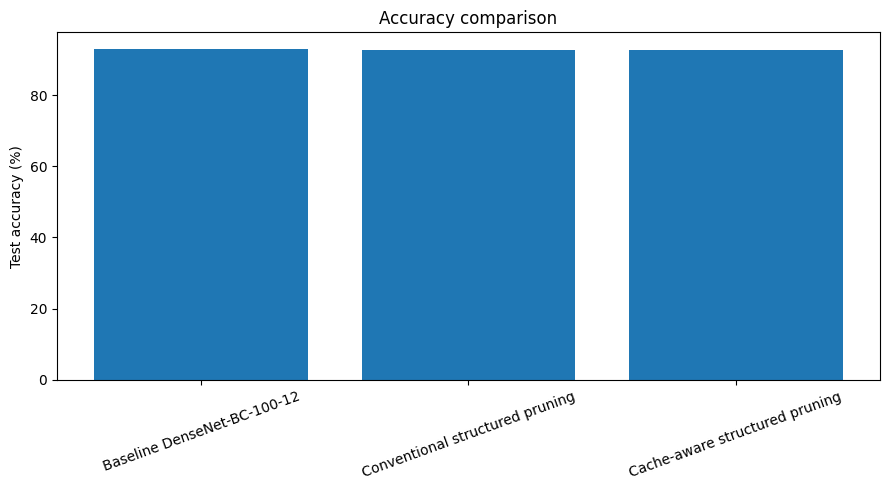

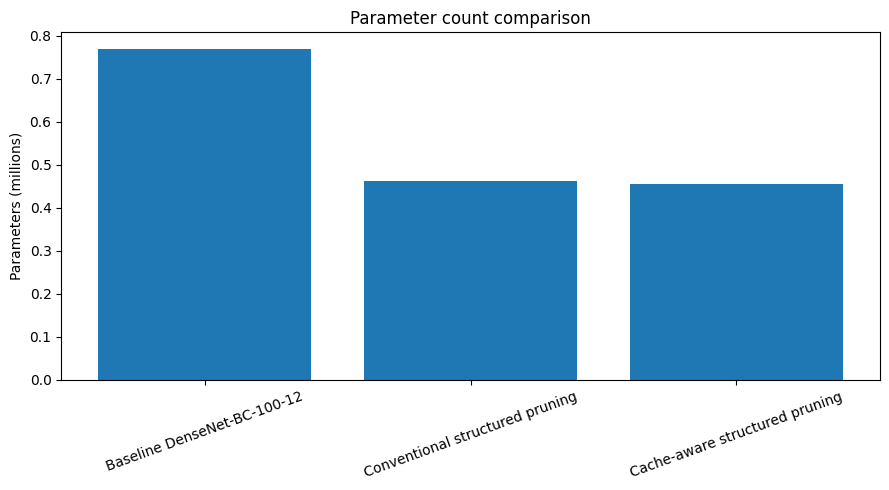

In [85]:

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["test_accuracy_percent"],
)

ax.set_ylabel("Test accuracy (%)")
ax.set_title("Accuracy comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["parameters"] / 1e6,
)

ax.set_ylabel("Parameters (millions)")
ax.set_title("Parameter count comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 33. Plot latency, GPU power and measured energy

**What happens in this cell:**  
Plots the hardware measurements that matter for the energy-efficiency objective.

If NVML was unavailable, the energy plot will contain missing values rather than fabricated numbers.

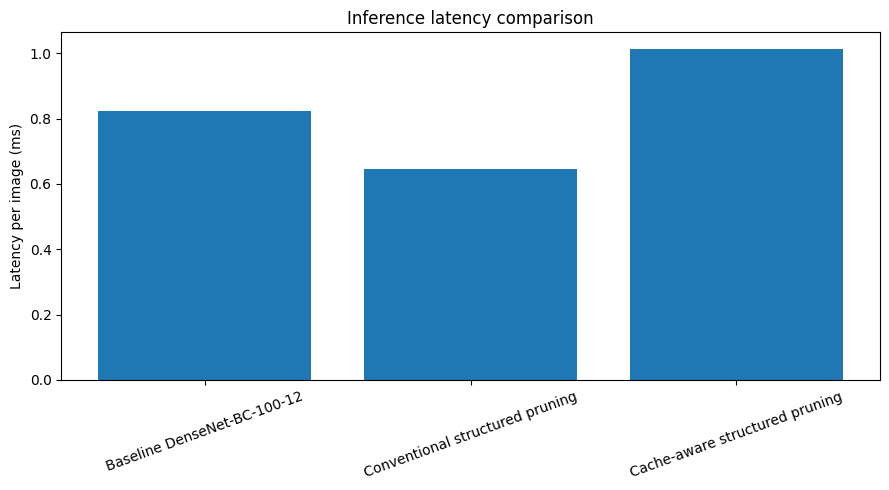

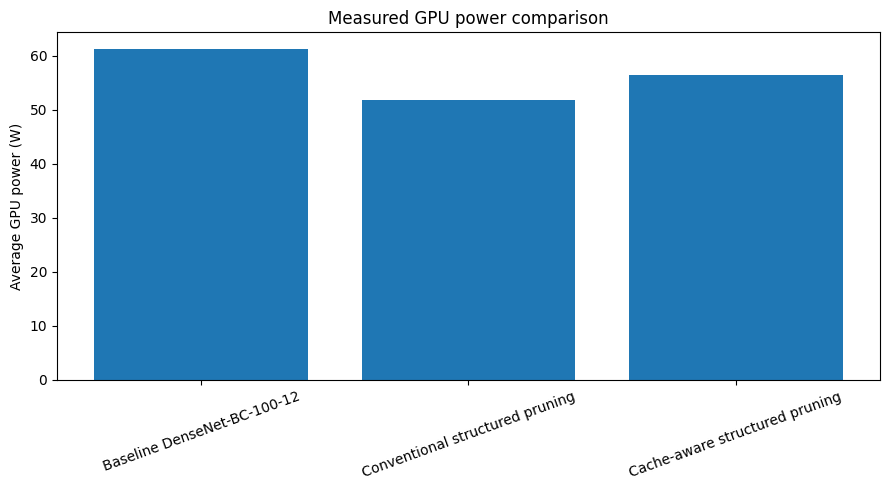

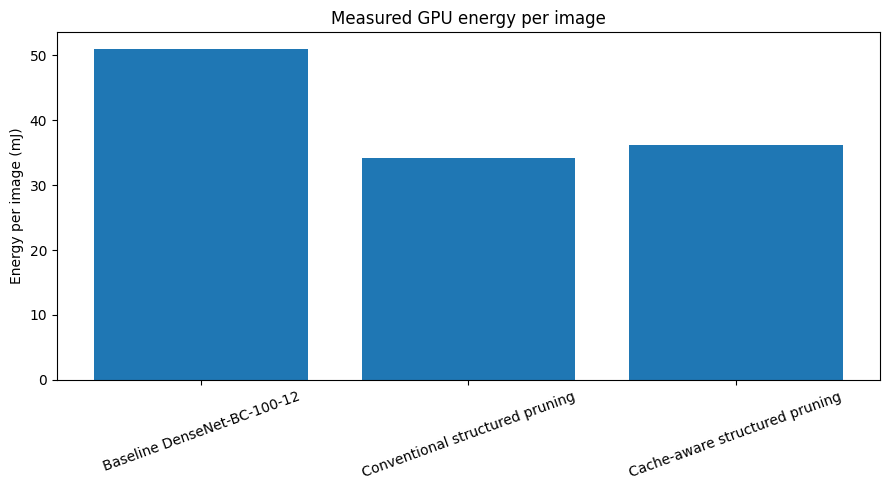

In [86]:

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["latency_image_ms"],
)

ax.set_ylabel("Latency per image (ms)")
ax.set_title("Inference latency comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["avg_gpu_power_w"],
)

ax.set_ylabel("Average GPU power (W)")
ax.set_title("Measured GPU power comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["energy_per_image_mj"],
)

ax.set_ylabel("Energy per image (mJ)")
ax.set_title("Measured GPU energy per image")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 34. Plot the cache-aware layer policy

**What happens in this cell:**  
Visualizes which convolutional layers received more pruning pressure from the cache-aware policy.

This plot is useful when explaining the research contribution to a supervisor.

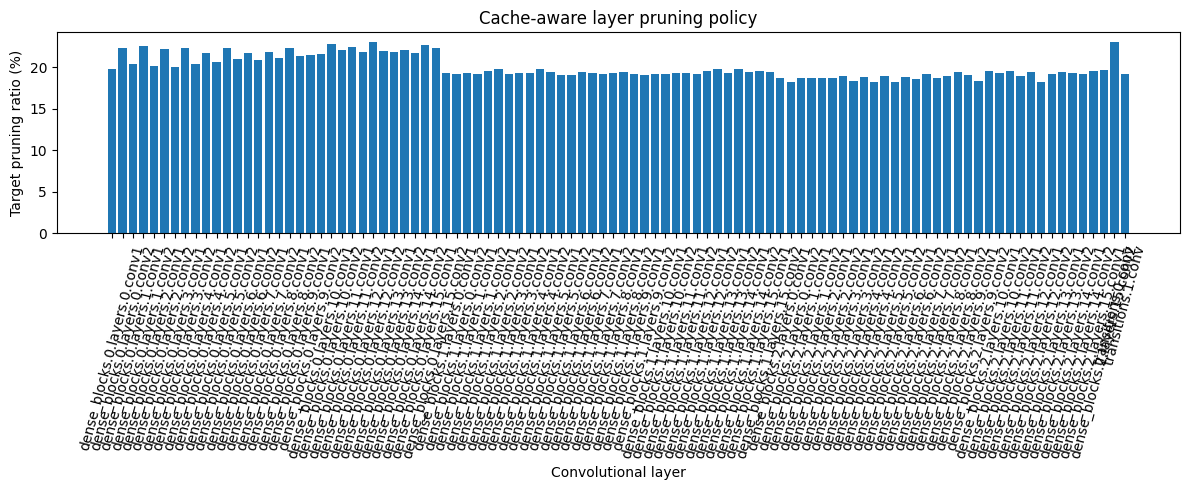

In [87]:

policy_plot = policy_df.copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    policy_plot["layer"],
    policy_plot["target_pruning_ratio"] * 100,
)

ax.set_ylabel("Target pruning ratio (%)")
ax.set_xlabel("Convolutional layer")
ax.set_title("Cache-aware layer pruning policy")
ax.tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()


## 35. Save all experiment metadata

**What happens in this cell:**  
Stores the configuration, GPU name and cache assumptions so the experiment can be reproduced later.

In [88]:
metadata = {
    "created_at_local": datetime.datetime.now().astimezone().isoformat(),
    "run_tag": RUN_TAG, "smoke_test": SMOKE_TEST,
    "architecture": "CIFAR DenseNet-BC-100-12", "depth": DENSENET_DEPTH, "growth_rate": DENSENET_GROWTH_RATE,
    "bottleneck_size": DENSENET_BOTTLENECK_SIZE, "compression": DENSENET_COMPRESSION,
    "dataset": "CIFAR-10", "seed": SEED, "batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
    "full_train_split_size": 50000 - VAL_SIZE, "full_validation_split_size": VAL_SIZE, "full_test_split_size": 10000,
    "images_used_this_run": {"train": len(train_dataset), "validation": len(val_dataset), "test": len(test_dataset)},
    "baseline_epochs": BASELINE_EPOCHS, "finetune_epochs": FINETUNE_EPOCHS, "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "momentum": MOMENTUM, "precision": "AMP" if AMP_ENABLED else "FP32",
    "conventional_pruning_method": "torch-pruning MetaPruner with magnitude importance and global pruning",
    "conventional_pruning_ratio_target": CONVENTIONAL_PRUNING_RATIO,
    "cache_aware_method": "layer-specific magnitude pruning ratios derived from normalized per-layer working-set/cache-pressure estimates; MetaPruner pruning_ratio_dict required",
    "cache_policy_formula": "clip(r_base + spread*(cache_aware_score - mean_cache_aware_score), min_ratio, max_ratio); cache_aware_score is the equal-weight mean of normalized inverse filter-L2 importance and normalized cache-pressure proxy; then calibrate a global ratio offset against conventional achieved MAC count",
    "cache_policy_spread": CACHE_POLICY_SPREAD, "cache_aware_min_ratio": CACHE_AWARE_MIN_RATIO, "cache_aware_max_ratio": CACHE_AWARE_MAX_RATIO,
    "cache_policy_calibration_offset": best_offset, "mac_reduction_gap_pp": mac_gap_pp,
    "round_to": ROUND_TO, "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU",
    "gpu_total_memory_bytes": int(torch.cuda.get_device_properties(0).total_memory) if DEVICE.type == "cuda" else None,
    "nvml_available": NVML_OK, "l2_cache_reference_mb": L2_CACHE_MB, "l2_cache_reference_source": L2_SOURCE,
    "l2_cache_measurement_note": "Working-set estimate only; no claim of measured L2 hit/miss counters.",
    "energy_measurement_note": "NVML power is total GPU power. Energy integrates sampled power over elapsed inference interval; incremental energy subtracts a short idle estimate when available.",
    "torch_version": torch.__version__, "torchvision_version": getattr(__import__("torchvision"), "__version__", "unknown"), "numpy_version": np.__version__, "pandas_version": pd.__version__, "matplotlib_version": plt.matplotlib.__version__, "cpu_processor": platform.processor(),
    "python_version": sys.version, "platform": platform.platform(),
    "torch_pruning_version": getattr(tp, "__version__", "unknown"), "fvcore_available": FVCORE_OK,
    "project_root": str(PROJECT_ROOT), "data_root": str(DATA_ROOT), "checkpoint_root": str(CHECKPOINT_ROOT), "result_root": str(RESULT_ROOT),
    "energy_warmup_batches": ENERGY_WARMUP_BATCHES, "energy_timed_batches": ENERGY_BATCHES, "power_sample_interval_sec": POWER_SAMPLE_INTERVAL_SEC, "idle_power_sample_sec": IDLE_POWER_SAMPLE_SEC,
    "resume_environment_variable": "RESUME_TRAINING=1 resumes latest checkpoints; configuration/run-tag must match",
}
with open(RESULT_ROOT / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)
print(json.dumps(metadata, indent=2, default=str))

{
  "created_at_local": "2026-10-29T04:18:06.178942+05:30",
  "run_tag": "college_v1_30e",
  "smoke_test": false,
  "architecture": "CIFAR DenseNet-BC-100-12",
  "depth": 100,
  "growth_rate": 12,
  "bottleneck_size": 4,
  "compression": 0.5,
  "dataset": "CIFAR-10",
  "seed": 42,
  "batch_size": 128,
  "num_workers": 0,
  "full_train_split_size": 45000,
  "full_validation_split_size": 5000,
  "full_test_split_size": 10000,
  "images_used_this_run": {
    "train": 45000,
    "validation": 5000,
    "test": 10000
  },
  "baseline_epochs": 30,
  "finetune_epochs": 8,
  "learning_rate": 0.1,
  "weight_decay": 0.0005,
  "momentum": 0.9,
  "precision": "AMP",
  "conventional_pruning_method": "torch-pruning MetaPruner with magnitude importance and global pruning",
  "conventional_pruning_ratio_target": 0.2,
  "cache_aware_method": "layer-specific magnitude pruning ratios derived from normalized per-layer working-set/cache-pressure estimates; MetaPruner pruning_ratio_dict required",
  "cache_

## 38. Final research checklist

Before reporting results, confirm all of the following:
- [ ] Set `SMOKE_TEST = False` and rerun the full experiment from the configuration cell.
- [ ] Inspect `results/final_three_way_comparison.csv` and `results/research_summary.md`.
- [ ] Confirm both pruning methods passed the physical structure, parameter/MAC reduction, and forward/backward checks.
- [ ] Confirm the achieved MAC reductions are sufficiently close for the intended comparison; if not, report the gap explicitly.
- [ ] Confirm `results/cache_aware_layer_policy.csv` shows applied layer-specific ratios and that no fallback was used.
- [ ] Check hardware measurement availability and repeat latency/energy measurements if making strong claims.
- [ ] Treat estimated working-set pressure as a proxy, not as measured L2 cache hit/miss evidence.
- [ ] Archive the notebook, `results/`, and `checkpoints/` together with the exact environment/software versions.

**No accuracy, latency, or energy result should be reported until the notebook has completed successfully on the target hardware.**

## 37. Final artifact generation and acceptance checks

This final section consolidates metrics from all three models, writes the required CSVs, creates and saves every required plot, creates a human-readable research summary, and verifies that expected artifacts exist. It does not invent unavailable energy or cache-counter measurements.

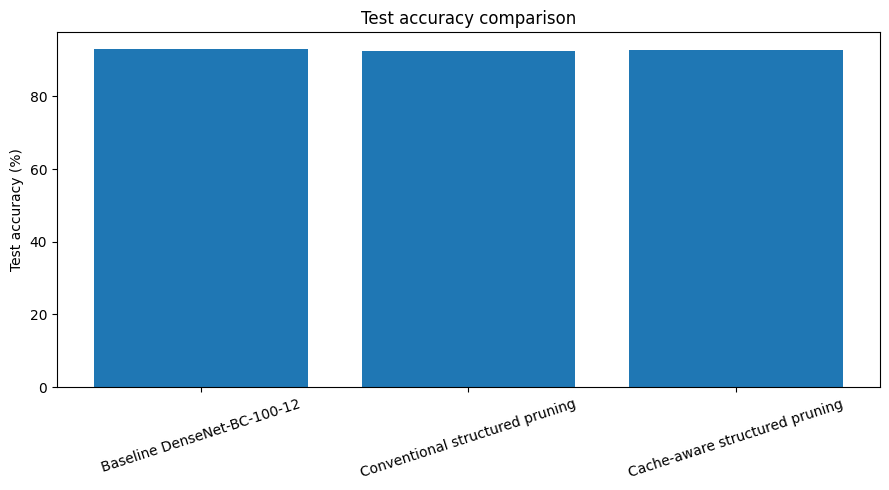

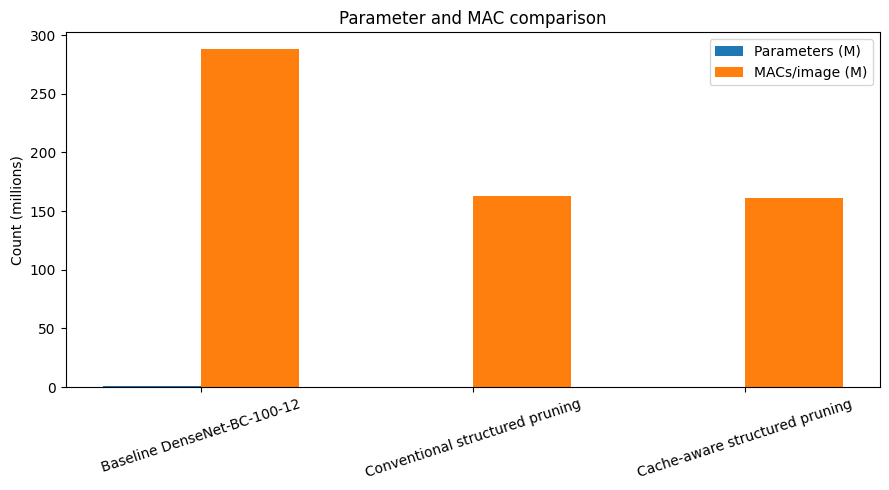

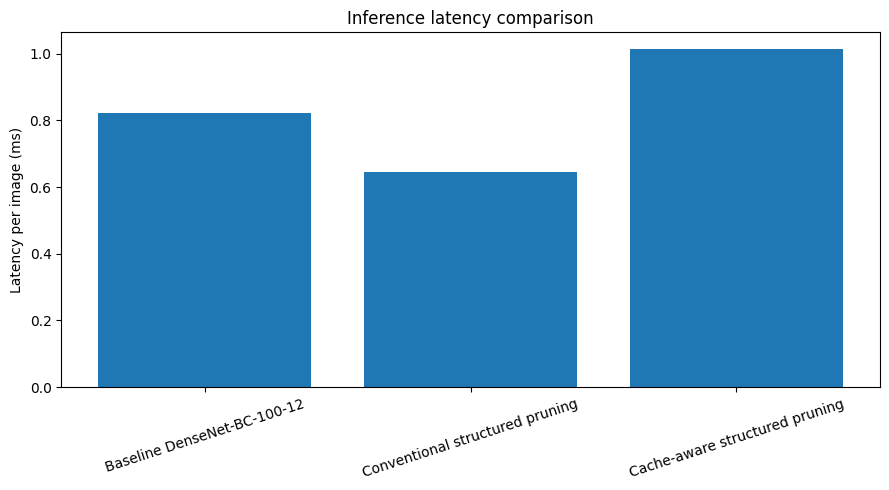

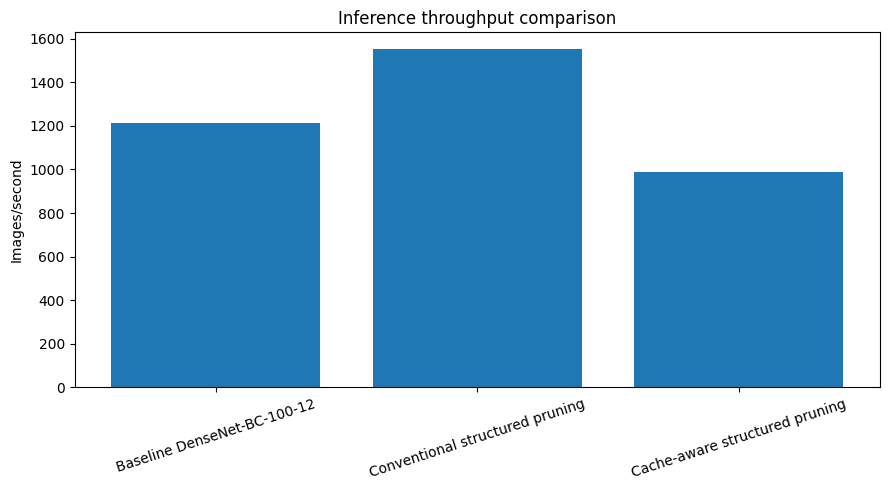

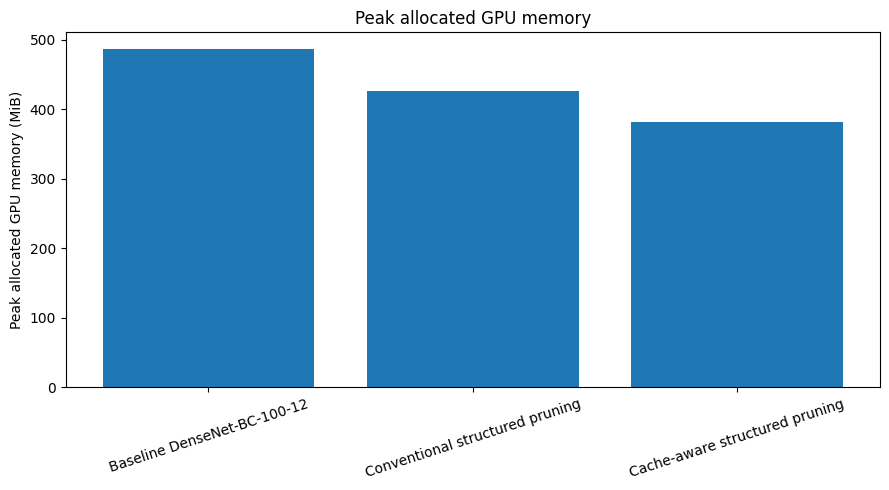

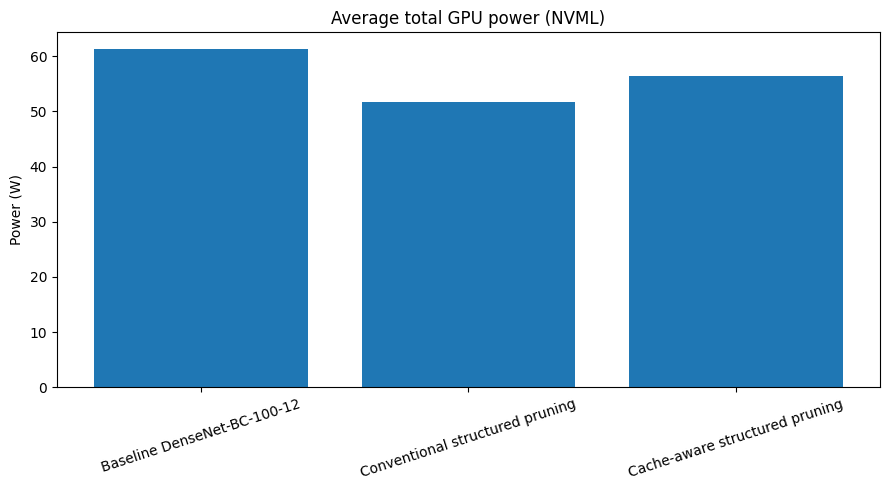

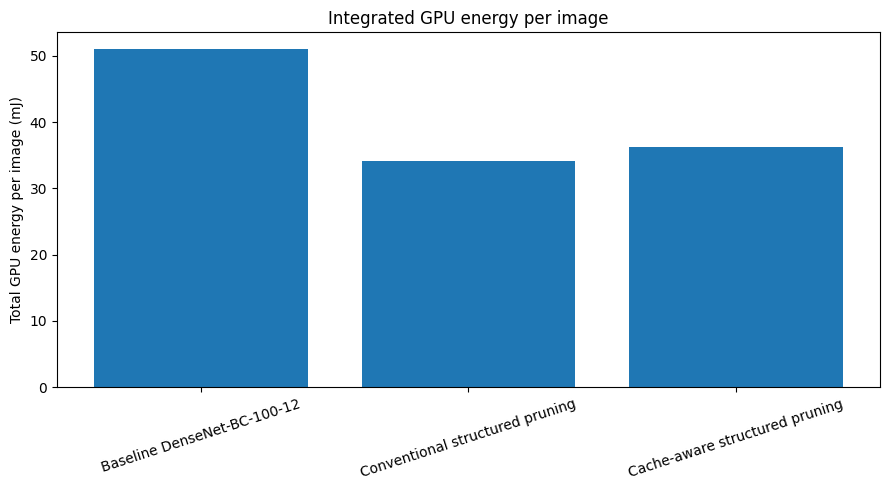

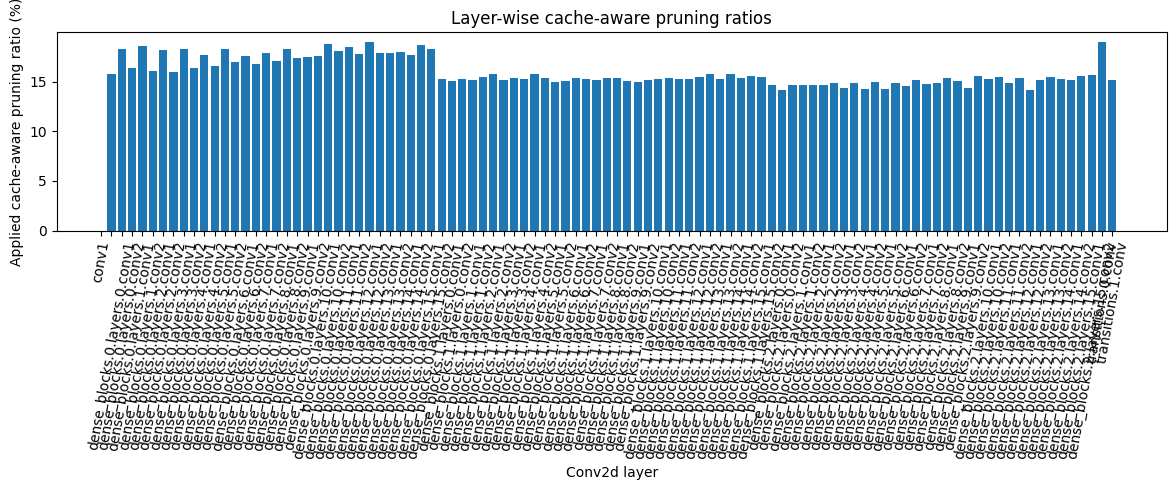

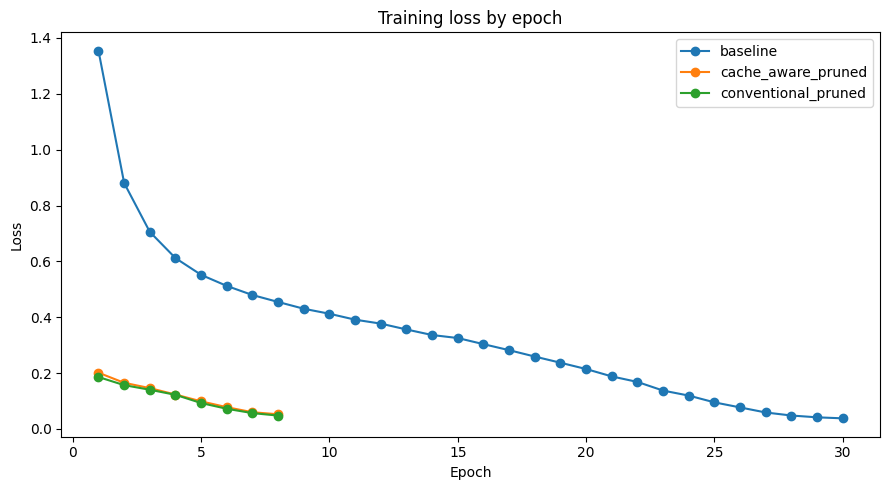

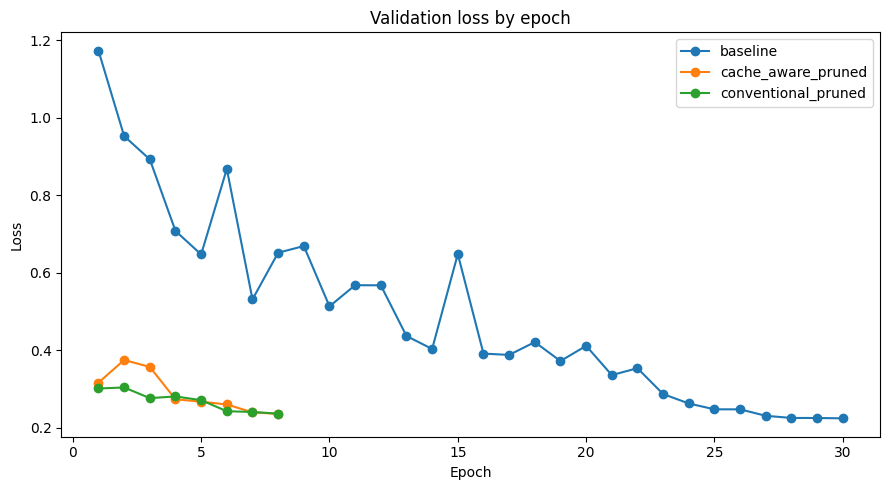

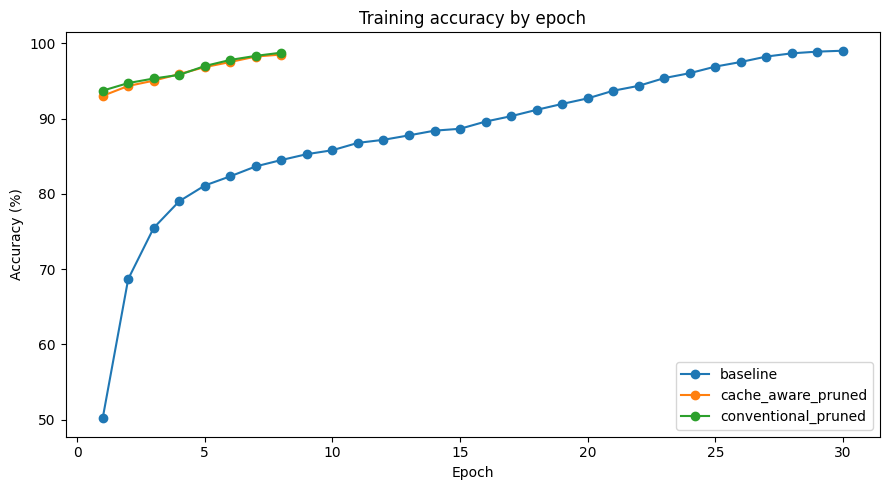

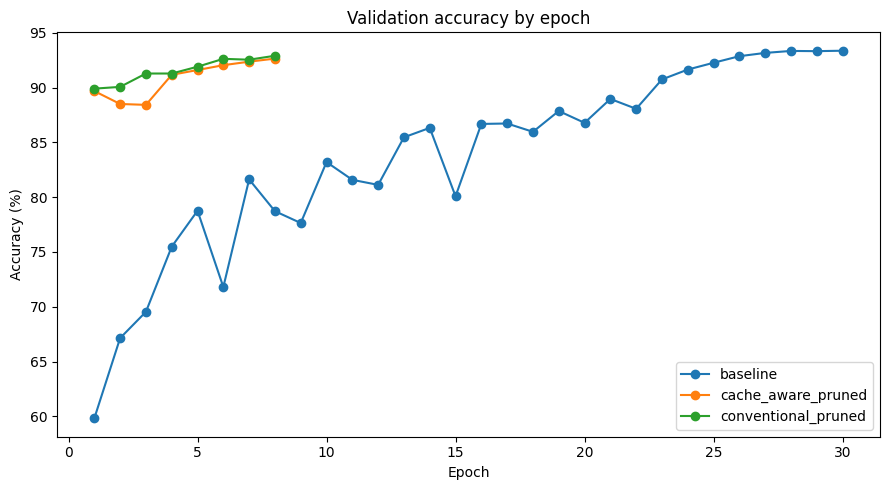

2026-10-29 04:18:08,957 | INFO | Final artifact generation complete. Required artifacts verified: 11/11



All required CSV/JSON/Markdown/log artifacts exist:
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\baseline_metrics.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\conventional_pruned_metrics.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\cache_aware_metrics.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\final_three_way_comparison.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\training_history.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\layer_pruning_report.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\baseline_cache_working_sets.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\cache_aware_layer_policy.csv
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\experiment_metadata.json
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\run.log
 ✓ c:\Users\Tankala Bhaskar teja\ML_RESEARCH_NEW\results\research_summary.md

Plots saved under: c:\Users\Tankala Bhaskar teja\ML

In [89]:
# Per-layer structural report: actual before/after Conv2d channel dimensions.
def make_layer_pruning_report(baseline_model, conventional_model, cache_model, cache_policy):
    base = convolution_channel_snapshot(baseline_model)
    conv = convolution_channel_snapshot(conventional_model)
    cache = convolution_channel_snapshot(cache_model)
    policy = cache_policy.set_index("layer").to_dict("index") if len(cache_policy) else {}
    rows = []
    for name, b in base.items():
        c = conv.get(name, {}); a = cache.get(name, {}); p = policy.get(name, {})
        rows.append({
            "layer": name,
            "baseline_in_channels": b["in_channels"], "baseline_out_channels": b["out_channels"],
            "conventional_in_channels": c.get("in_channels", np.nan), "conventional_out_channels": c.get("out_channels", np.nan),
            "conventional_out_channel_reduction_percent": 100 * (b["out_channels"] - c.get("out_channels", b["out_channels"])) / max(b["out_channels"], 1),
            "cache_aware_in_channels": a.get("in_channels", np.nan), "cache_aware_out_channels": a.get("out_channels", np.nan),
            "cache_aware_out_channel_reduction_percent": 100 * (b["out_channels"] - a.get("out_channels", b["out_channels"])) / max(b["out_channels"], 1),
            "cache_target_pruning_ratio": p.get("target_pruning_ratio", np.nan),
            "cache_applied_pruning_ratio": p.get("applied_pruning_ratio", np.nan),
            "working_set_mb": p.get("working_set_mb", np.nan), "cache_pressure_ratio": p.get("cache_pressure_ratio", np.nan),
        })
    return pd.DataFrame(rows)

layer_pruning_report = make_layer_pruning_report(baseline, conventional_model, cache_aware_model, policy_df)
layer_pruning_report.to_csv(RESULT_ROOT / "layer_pruning_report.csv", index=False)

# Save compact model-only checkpoints for deployment-size measurement; training checkpoints retain optimizer/scheduler state for resumption.
BASELINE_INFERENCE_WEIGHTS = CHECKPOINT_ROOT / f"baseline_inference_weights_{RUN_TAG}.pt"
CONVENTIONAL_INFERENCE_WEIGHTS = CHECKPOINT_ROOT / f"conventional_pruned_inference_weights_{RUN_TAG}.pt"
CACHE_INFERENCE_WEIGHTS = CHECKPOINT_ROOT / f"cache_aware_pruned_inference_weights_{RUN_TAG}.pt"
torch.save(baseline.state_dict(), BASELINE_INFERENCE_WEIGHTS)
torch.save(conventional_model.state_dict(), CONVENTIONAL_INFERENCE_WEIGHTS)
torch.save(cache_aware_model.state_dict(), CACHE_INFERENCE_WEIGHTS)

# Store model-specific metric files, including actual serialized inference-weight file sizes and total training time.
metric_records = [baseline_metrics.copy(), conventional_metrics.copy(), cache_metrics.copy()]
checkpoint_paths = [BASELINE_INFERENCE_WEIGHTS, CONVENTIONAL_INFERENCE_WEIGHTS, CACHE_INFERENCE_WEIGHTS]
history_path_by_model = {
    "Baseline DenseNet-BC-100-12": RESULT_ROOT / f"baseline_history_{RUN_TAG}.csv",
    "Conventional structured pruning": RESULT_ROOT / f"conventional_pruned_history_{RUN_TAG}.csv",
    "Cache-aware structured pruning": RESULT_ROOT / f"cache_aware_history_{RUN_TAG}.csv",
}
for rec, path in zip(metric_records, checkpoint_paths):
    rec["checkpoint_file_size_mb"] = file_size_mb(path)
    rec["checkpoint_path"] = str(path)
    hp = history_path_by_model.get(rec["model"])
    if hp is not None and hp.exists():
        _hist = pd.read_csv(hp)
        rec["total_training_time_sec"] = float(_hist["epoch_time_sec"].sum()) if "epoch_time_sec" in _hist else float("nan")
        rec["epochs_completed"] = int(_hist["epoch"].max()) if "epoch" in _hist and len(_hist) else 0
    else:
        rec["total_training_time_sec"] = float("nan")
        rec["epochs_completed"] = 0
baseline_metrics, conventional_metrics, cache_metrics = metric_records
pd.DataFrame([baseline_metrics]).to_csv(RESULT_ROOT / "baseline_metrics.csv", index=False)
pd.DataFrame([conventional_metrics]).to_csv(RESULT_ROOT / "conventional_pruned_metrics.csv", index=False)
pd.DataFrame([cache_metrics]).to_csv(RESULT_ROOT / "cache_aware_metrics.csv", index=False)

comparison = pd.DataFrame(metric_records)
base = comparison.iloc[0]
comparison["accuracy_change_pp_vs_baseline"] = comparison["test_accuracy_percent"] - base["test_accuracy_percent"]
comparison["parameter_reduction_percent"] = 100 * (base["parameters"] - comparison["parameters"]) / base["parameters"]
comparison["mac_reduction_percent"] = 100 * (base["macs_per_image"] - comparison["macs_per_image"]) / base["macs_per_image"]
comparison["estimated_flop_reduction_percent"] = 100 * (base["flops_per_image_estimated"] - comparison["flops_per_image_estimated"]) / base["flops_per_image_estimated"]
comparison["tensor_storage_reduction_percent"] = 100 * (base["model_tensor_storage_mb"] - comparison["model_tensor_storage_mb"]) / base["model_tensor_storage_mb"]
comparison["checkpoint_file_size_reduction_percent"] = 100 * (base["checkpoint_file_size_mb"] - comparison["checkpoint_file_size_mb"]) / base["checkpoint_file_size_mb"]
comparison["latency_change_percent_vs_baseline"] = 100 * (comparison["latency_image_ms"] - base["latency_image_ms"]) / base["latency_image_ms"]
comparison["throughput_change_percent_vs_baseline"] = 100 * (comparison["throughput_images_per_sec"] - base["throughput_images_per_sec"]) / base["throughput_images_per_sec"]
if "energy_per_image_mj" in comparison.columns and np.isfinite(base.get("energy_per_image_mj", np.nan)) and float(base.get("energy_per_image_mj", 0) or 0) != 0:
    comparison["energy_per_image_change_percent_vs_baseline"] = 100 * (comparison["energy_per_image_mj"] - base["energy_per_image_mj"]) / base["energy_per_image_mj"]
else:
    comparison["energy_per_image_change_percent_vs_baseline"] = np.nan
comparison.to_csv(RESULT_ROOT / "final_three_way_comparison.csv", index=False)

# Combined history (includes all epochs actually run; histories are persisted during training).
history_files = [RESULT_ROOT / f"baseline_history_{RUN_TAG}.csv", RESULT_ROOT / f"conventional_pruned_history_{RUN_TAG}.csv", RESULT_ROOT / f"cache_aware_history_{RUN_TAG}.csv"]
histories = []
for hp in history_files:
    if hp.exists(): histories.append(pd.read_csv(hp))
if histories:
    pd.concat(histories, ignore_index=True, sort=False).to_csv(RESULT_ROOT / "training_history.csv", index=False)
else:
    pd.DataFrame(columns=["model", "epoch", "train_loss", "train_accuracy_percent", "validation_loss", "validation_accuracy_percent", "epoch_time_sec", "learning_rate"]).to_csv(RESULT_ROOT / "training_history.csv", index=False)

# Save all required plots to disk. Each plot is also displayed in the notebook.
def save_bar_plot(x, y, ylabel, title, filename, rotation=18):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x, y)
    ax.set_ylabel(ylabel); ax.set_title(title); ax.tick_params(axis="x", rotation=rotation)
    fig.tight_layout(); fig.savefig(PLOT_ROOT / filename, dpi=160, bbox_inches="tight"); plt.show(); plt.close(fig)

labels = comparison["model"].tolist()
save_bar_plot(labels, comparison["test_accuracy_percent"], "Test accuracy (%)", "Test accuracy comparison", "accuracy_comparison.png")
fig, ax = plt.subplots(figsize=(9, 5)); width = 0.36; x = np.arange(len(comparison))
ax.bar(x - width/2, comparison["parameters"] / 1e6, width, label="Parameters (M)")
ax.bar(x + width/2, comparison["macs_per_image"] / 1e6, width, label="MACs/image (M)")
ax.set_xticks(x, labels, rotation=18); ax.set_ylabel("Count (millions)"); ax.set_title("Parameter and MAC comparison"); ax.legend(); fig.tight_layout(); fig.savefig(PLOT_ROOT / "parameters_and_macs.png", dpi=160, bbox_inches="tight"); plt.show(); plt.close(fig)
save_bar_plot(labels, comparison["latency_image_ms"], "Latency per image (ms)", "Inference latency comparison", "latency_comparison.png")
save_bar_plot(labels, comparison["throughput_images_per_sec"], "Images/second", "Inference throughput comparison", "throughput_comparison.png")
save_bar_plot(labels, comparison["peak_gpu_memory_allocated_mb"], "Peak allocated GPU memory (MiB)", "Peak allocated GPU memory", "gpu_memory_comparison.png")
fig, ax = plt.subplots(figsize=(9, 5)); ax.bar(labels, comparison["avg_gpu_power_w"], label="Average total GPU power (W)"); ax.set_ylabel("Power (W)"); ax.set_title("Average total GPU power (NVML)"); ax.tick_params(axis="x", rotation=18); fig.tight_layout(); fig.savefig(PLOT_ROOT / "power_comparison.png", dpi=160, bbox_inches="tight"); plt.show(); plt.close(fig)
save_bar_plot(labels, comparison["energy_per_image_mj"], "Total GPU energy per image (mJ)", "Integrated GPU energy per image", "energy_comparison.png")
fig, ax = plt.subplots(figsize=(12, 5)); ax.bar(layer_pruning_report["layer"], layer_pruning_report["cache_applied_pruning_ratio"] * 100); ax.set_ylabel("Applied cache-aware pruning ratio (%)"); ax.set_xlabel("Conv2d layer"); ax.set_title("Layer-wise cache-aware pruning ratios"); ax.tick_params(axis="x", rotation=80); fig.tight_layout(); fig.savefig(PLOT_ROOT / "layer_pruning_ratios.png", dpi=160, bbox_inches="tight"); plt.show(); plt.close(fig)

# Training/validation curves.
if len(pd.read_csv(RESULT_ROOT / "training_history.csv")):
    all_hist = pd.read_csv(RESULT_ROOT / "training_history.csv")
    for metric, ylabel, filename, title in [("train_loss", "Loss", "training_loss_curve.png", "Training loss by epoch"), ("validation_loss", "Loss", "validation_loss_curve.png", "Validation loss by epoch"), ("train_accuracy_percent", "Accuracy (%)", "training_accuracy_curve.png", "Training accuracy by epoch"), ("validation_accuracy_percent", "Accuracy (%)", "validation_accuracy_curve.png", "Validation accuracy by epoch")]:
        if metric not in all_hist.columns: continue
        fig, ax = plt.subplots(figsize=(9, 5))
        for model_name, group in all_hist.groupby("model"):
            ax.plot(group["epoch"], group[metric], marker="o", label=model_name)
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(); fig.tight_layout(); fig.savefig(PLOT_ROOT / filename, dpi=160, bbox_inches="tight"); plt.show(); plt.close(fig)

# Write research summary with measured values only and explicit limitations.
def fmt(value, digits=4):
    try:
        value = float(value)
        return "unavailable" if not np.isfinite(value) else f"{value:.{digits}f}"
    except Exception: return "unavailable"
lines = [
    "# Cache-Aware Structured Pruning — Research Run Summary", "",
    f"- Run mode: **{RUN_TAG}** (smoke test={SMOKE_TEST})",
    f"- Architecture: DenseNet-BC-100-12; dataset: CIFAR-10",
    f"- Device: {DEVICE}; GPU: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}",
    f"- Precision: {'AMP' if AMP_ENABLED else 'FP32'}; seed: {SEED}",
    f"- Cache reference: {L2_CACHE_MB:.3f} MiB ({L2_SOURCE})",
    "- Cache working-set estimates are proxies; no hardware L2 hit/miss counter result is claimed.",
    "- Checkpoint file size refers to serialized model-only inference weights; separate best/latest training checkpoints preserve optimizer/scheduler state for recovery.",
    "- NVML power is total device power. Integrated energy is the trapezoidal integral of sampled power; incremental energy subtracts an idle estimate when available.",
    "", "## Three-way measured comparison", "",
    comparison[["model", "test_loss", "test_accuracy_percent", "parameters", "macs_per_image", "checkpoint_file_size_mb", "total_training_time_sec", "latency_image_ms", "latency_batch_median_ms", "throughput_images_per_sec", "peak_gpu_memory_allocated_mb", "peak_gpu_memory_reserved_mb", "avg_gpu_power_w", "energy_per_image_mj", "parameter_reduction_percent", "mac_reduction_percent"]].to_string(index=False),
    "", "## Interpretation guardrails", "",
    f"- Difference in achieved MAC reduction between conventional and cache-aware pruning: **{mac_gap_pp:.3f} percentage points**.",
    f"- Matching tolerance configured: {MAC_REDUCTION_TOLERANCE_PP:.1f} percentage points.",
    "- Report only the measurements above. A smoke-test run is for pipeline validation and must not be treated as a final accuracy benchmark.",
    "- Latency and energy depend on hardware, runtime load, precision, and measurement conditions; repeat measurements for a research claim.",
    "- FLOPs are estimated as 2 × Conv/Linear MACs; non-Conv/Linear operations are not included in this estimate.",
]
(RESULT_ROOT / "research_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

# Refresh metadata after calibration/artifact generation.
metadata.update({"completed_at_local": datetime.datetime.now().astimezone().isoformat(), "final_artifact_count_expected": 11, "cache_policy_calibration_offset": best_offset, "achieved_mac_reduction_gap_percentage_points": mac_gap_pp, "plots_directory": str(PLOT_ROOT)})
with open(RESULT_ROOT / "experiment_metadata.json", "w", encoding="utf-8") as f: json.dump(metadata, f, indent=2, default=str)

required_artifacts = [
    RESULT_ROOT / "baseline_metrics.csv", RESULT_ROOT / "conventional_pruned_metrics.csv", RESULT_ROOT / "cache_aware_metrics.csv",
    RESULT_ROOT / "final_three_way_comparison.csv", RESULT_ROOT / "training_history.csv", RESULT_ROOT / "layer_pruning_report.csv",
    RESULT_ROOT / "baseline_cache_working_sets.csv", RESULT_ROOT / "cache_aware_layer_policy.csv", RESULT_ROOT / "experiment_metadata.json",
    RESULT_ROOT / "run.log", RESULT_ROOT / "research_summary.md",
]
missing_artifacts = [str(p) for p in required_artifacts if not p.exists()]
if missing_artifacts: raise RuntimeError("Required output artifacts are missing: " + ", ".join(missing_artifacts))
logging.info("Final artifact generation complete. Required artifacts verified: %d/%d", len(required_artifacts) - len(missing_artifacts), len(required_artifacts))
print("\nAll required CSV/JSON/Markdown/log artifacts exist:")
for p in required_artifacts: print(" ✓", p)
print("\nPlots saved under:", PLOT_ROOT)
print("\nFinal three-way comparison:")
print(comparison.to_string(index=False))